# Review 3 -- Model Building and Comparison Analysis
**Food Waste Prediction and Meal-Planning Optimization for Event Catering**

This notebook executes the full Review 3 workflow end to end on the leakage-safe split from Review 2:

| Deliverable | Section |
|---|---|
| Extended EDA across every column (carried into model design) | A |
| 1. Model selection and justification | 1 |
| 2. Model development (train/test split + 5-fold CV) | 2 |
| 3. Model evaluation (MAE, MSE, RMSE, R2 / Accuracy, Precision, Recall, F1, ROC-AUC, confusion matrix) | 3 |
| 4. Model performance comparison (tables, charts, strengths and limitations) | 4 |
| 5. Hyperparameter tuning (Grid Search, Randomized Search) and before/after comparison | 5 |
| 6. Final model selection with statistical justification | 6 |
| End-to-end product: prescriptive engine and dashboard inference path | 7 |

Two tasks are solved: **regression** of `wastage_food_amount` and **classification** of the LOW / MEDIUM / HIGH risk tier.

In [1]:
%matplotlib inline
import sys, pathlib, json, warnings
ROOT = pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Image, display
import pipeline as P
import eda_extended as E
import train_models as T
get_ipython().run_line_magic('matplotlib', 'inline')   # the modules force the Agg backend on import
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 30); pd.set_option('display.width', 200)

D = T.prepare_data()          # runs the Review 2 pipeline: clean -> split -> tiers -> features -> encode
train_df, test_df = D['artifacts']['train_df'], D['artifacts']['test_df']
print('Design matrix:', D['X_train'].shape, 'train /', D['X_test'].shape, 'test')
print('Risk-tier cut points (training quantiles): Q1 =', D['q1'], ' Q3 =', D['q3'])

{
  "raw_shape": [
    1782,
    11
  ],
  "cleaned_shape": [
    1618,
    11
  ],
  "train_shape": [
    1294,
    12
  ],
  "test_shape": [
    324,
    12
  ],
  "risk_tier_cutpoints": {
    "Q1": 20.0,
    "Q3": 35.0
  },
  "risk_tier_distribution": {
    "train": {
      "MEDIUM": 0.509,
      "HIGH": 0.342,
      "LOW": 0.15
    },
    "test": {
      "MEDIUM": 0.5,
      "HIGH": 0.364,
      "LOW": 0.136
    }
  },
  "ks_test_train_vs_test_target": {
    "statistic": 0.0456,
    "p_value": 0.6346
  },
  "attainable_ceiling": {
    "dof_all_features": 58,
    "residual_variance_all_features": 26.845,
    "dof_strong_features": 1502,
    "residual_variance_strong_features": 7.264,
    "implied_r2_ceiling": 0.9328
  },
  "feature_columns": [
    "number_of_guests",
    "quantity_of_food",
    "food_per_guest",
    "surplus_units",
    "pricing_ordinal",
    "is_high_price",
    "is_sit_down",
    "guest_scale",
    "type_of_food",
    "event_type",
    "storage_conditions",
    "p

## A. Extended exploratory analysis across every column
Review 2 focused on the two dominant drivers. Here every categorical column is examined against waste, the
waste *rate*, the risk tier, and against each other. All statistics use the **training partition only**.

In [2]:
E.numeric_summary(train_df)

,column,mean,std,min,q1,median,q3,max,skew,kurtosis,distinct_values
0,number_of_guests,318.223,67.783,207.000,267.000,302.000,367.000,491.000,0.419,-0.556,39
1,quantity_of_food,411.898,64.854,280.000,350.000,400.000,480.000,500.000,-0.143,-1.111,30
2,food_per_guest,1.314,0.183,0.873,1.246,1.282,1.357,2.165,2.148,7.698,59
3,wastage_food_amount,28.538,10.401,10.000,20.000,25.000,35.000,63.000,0.513,-0.318,25
4,waste_pct,6.841,1.981,2.083,5.556,6.432,8.000,15.429,0.471,-0.141,63
5,waste_per_guest,0.089,0.025,0.026,0.071,0.083,0.105,0.171,0.689,0.249,77


In [3]:
cat = E.category_summary(train_df)
cat

,column,level,n,share_pct,mean_waste,median_waste,std_waste,mean_waste_pct,mean_guests,mean_quantity,high_risk_share_pct
0,type_of_food,Baked Goods,304,23.493,28.375,25.0,10.506,6.809,317.352,410.401,33.882
1,type_of_food,Dairy Products,273,21.097,28.125,25.0,10.493,6.800,316.689,409.026,34.066
2,type_of_food,Fruits,236,18.238,29.627,30.0,10.877,6.992,326.784,418.178,37.288
3,type_of_food,Meat,317,24.498,28.757,27.0,10.421,6.830,317.341,416.038,33.754
4,type_of_food,Vegetables,164,12.674,27.537,26.0,9.215,6.776,311.774,402.415,31.098
5,event_type,Birthday,272,21.020,28.316,25.0,9.499,6.786,324.478,412.551,30.147
6,event_type,Corporate,365,28.207,28.422,25.0,11.130,6.815,316.079,411.030,33.699
7,event_type,Social Gathering,331,25.580,28.251,27.0,10.161,6.836,314.275,407.686,31.118
8,event_type,Wedding,326,25.193,29.144,27.0,10.538,6.923,319.411,416.601,41.104
9,storage_conditions,Refrigerated,452,34.930,28.646,27.0,10.050,6.846,316.122,414.046,33.407


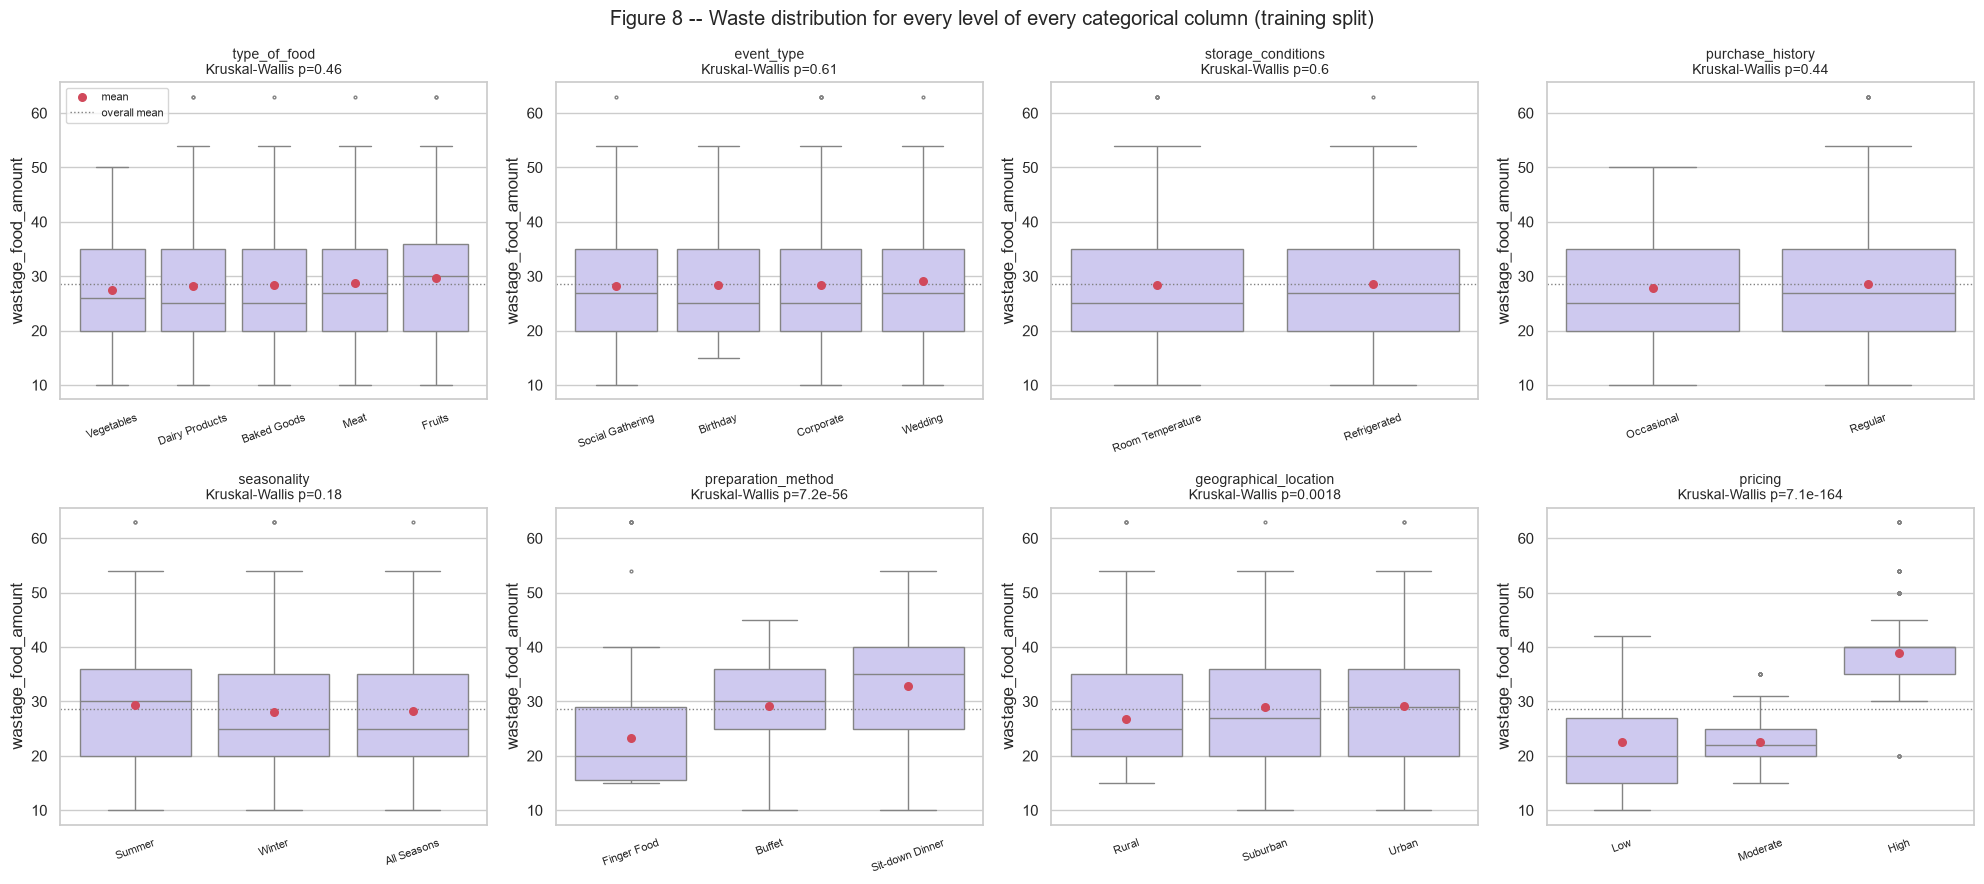

In [4]:
fig = E.fig_waste_by_every_category(train_df); display(fig); plt.close(fig)

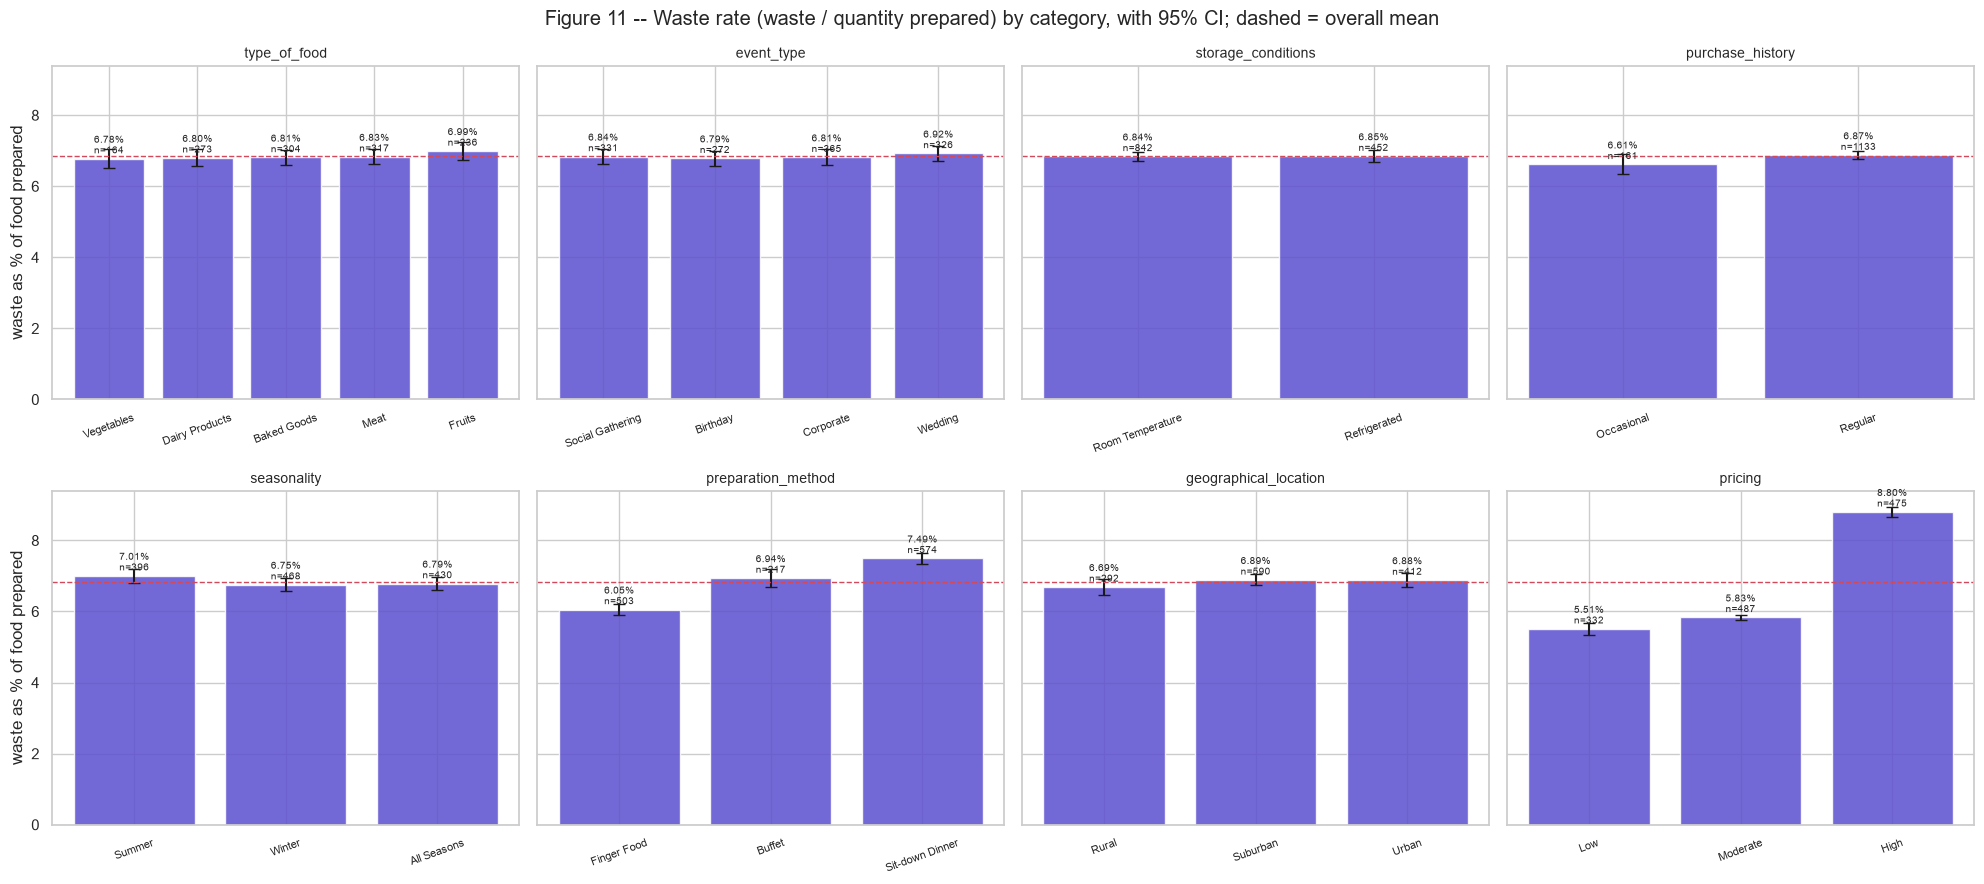

In [5]:
fig = E.fig_waste_rate_by_category(train_df); display(fig); plt.close(fig)

**Reading:** waste *rate* (waste / quantity prepared) separates the same two columns as raw waste --
pricing tier and preparation method -- so the effect is not just a by-product of larger events preparing more food.

In [6]:
assoc = E.risk_tier_association(train_df)
assoc

,feature,chi2,dof,p_value,cramers_v,association
0,pricing,783.55,4,2.814132e-168,0.549,Strong
1,guest_scale,386.84,6,1.885302e-80,0.384,Strong
2,preparation_method,267.02,4,1.403125e-56,0.319,Strong
3,geographical_location,15.80,4,3.292782e-03,0.068,Weak/none
4,event_type,17.03,6,9.179470e-03,0.065,Weak/none
5,storage_conditions,6.38,2,4.117151e-02,0.058,Weak/none
6,seasonality,11.16,4,2.481272e-02,0.053,Weak/none
7,purchase_history,2.91,2,2.329857e-01,0.027,Weak/none
8,type_of_food,4.09,8,8.493444e-01,0.000,Weak/none


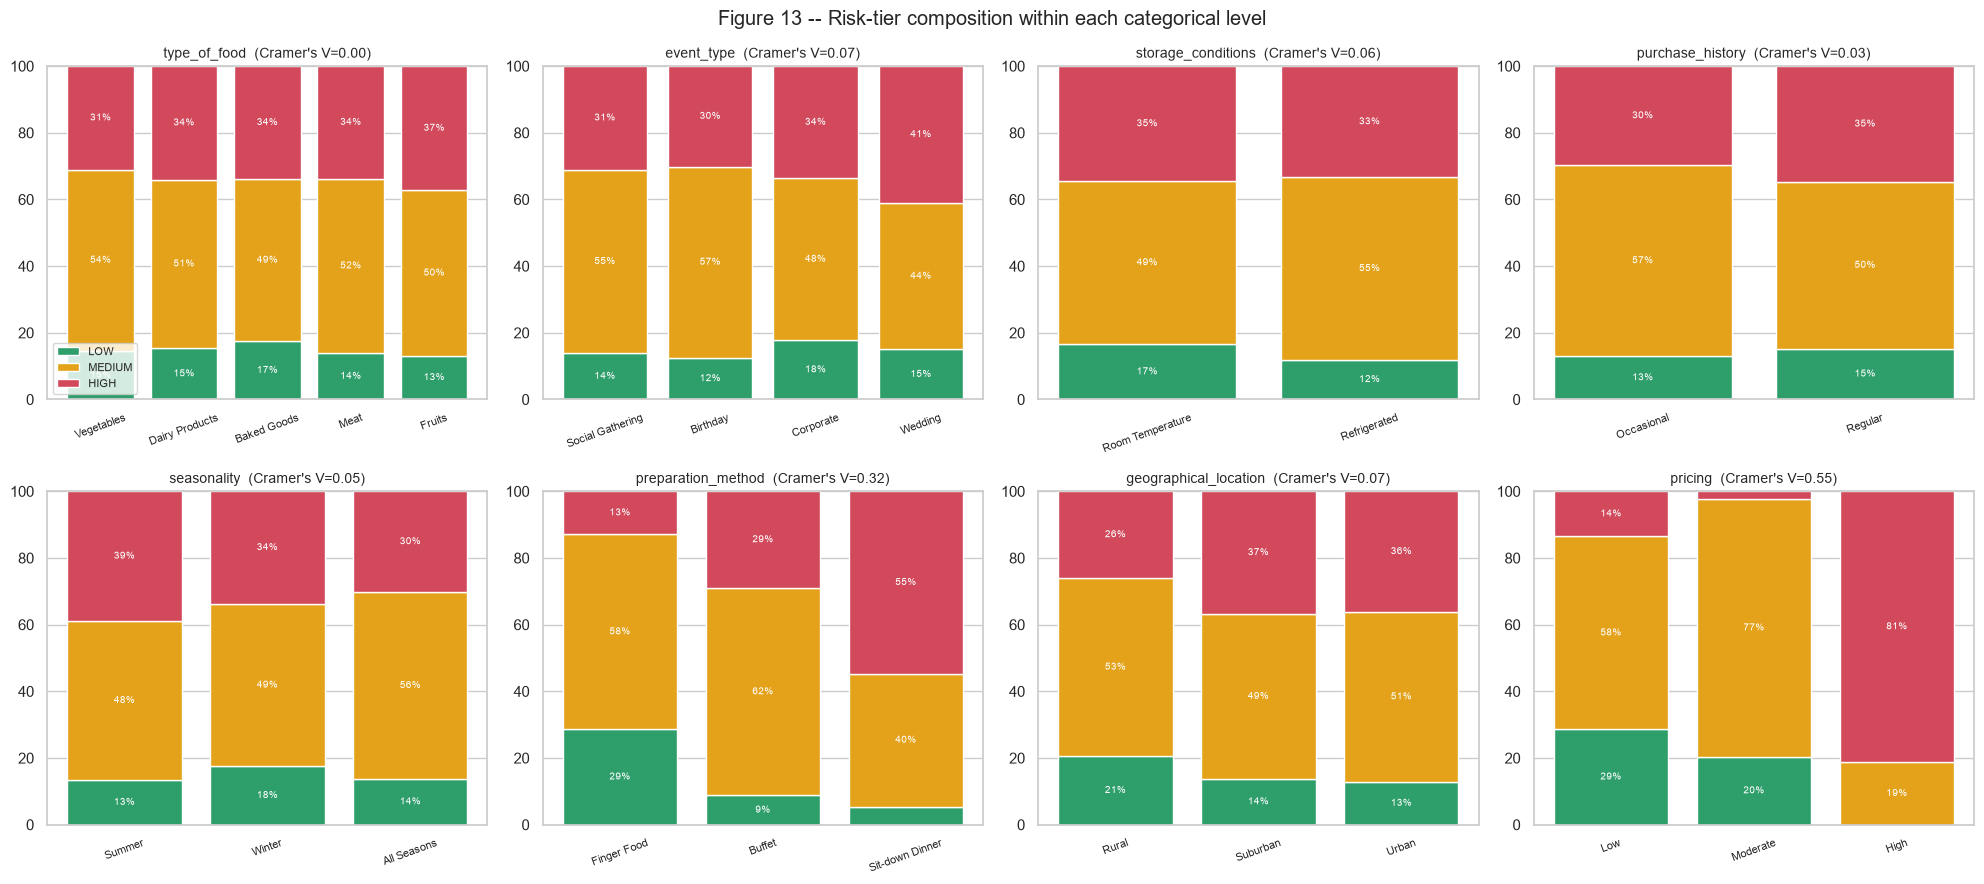

In [7]:
fig = E.fig_risk_tier_composition(train_df); display(fig); plt.close(fig)

In [8]:
anova = pd.DataFrame([E.two_way_anova(train_df, a, b) for a, b in E.TWO_WAY_PAIRS + [('pricing','preparation_method')]])
anova

,factor_a,factor_b,F_a,p_a,partial_eta2_a,F_b,p_b,partial_eta2_b,F_ab,p_ab,partial_eta2_ab
0,event_type,type_of_food,0.51,6.778857e-01,0.0012,1.12,3.448650e-01,0.0035,0.40,9.635086e-01,0.0038
1,seasonality,storage_conditions,1.62,1.980728e-01,0.0025,0.01,9.338008e-01,0.0000,0.07,9.342524e-01,0.0001
2,geographical_location,pricing,14.25,7.540230e-07,0.0217,949.47,6.532770e-254,0.5964,1.86,1.153416e-01,0.0058
3,purchase_history,event_type,0.81,3.670313e-01,0.0006,0.65,5.807555e-01,0.0015,0.13,9.420855e-01,0.0003
4,pricing,preparation_method,1105.87,4.645333e-280,0.6325,118.34,6.715203e-48,0.1555,11.54,3.278580e-09,0.0347


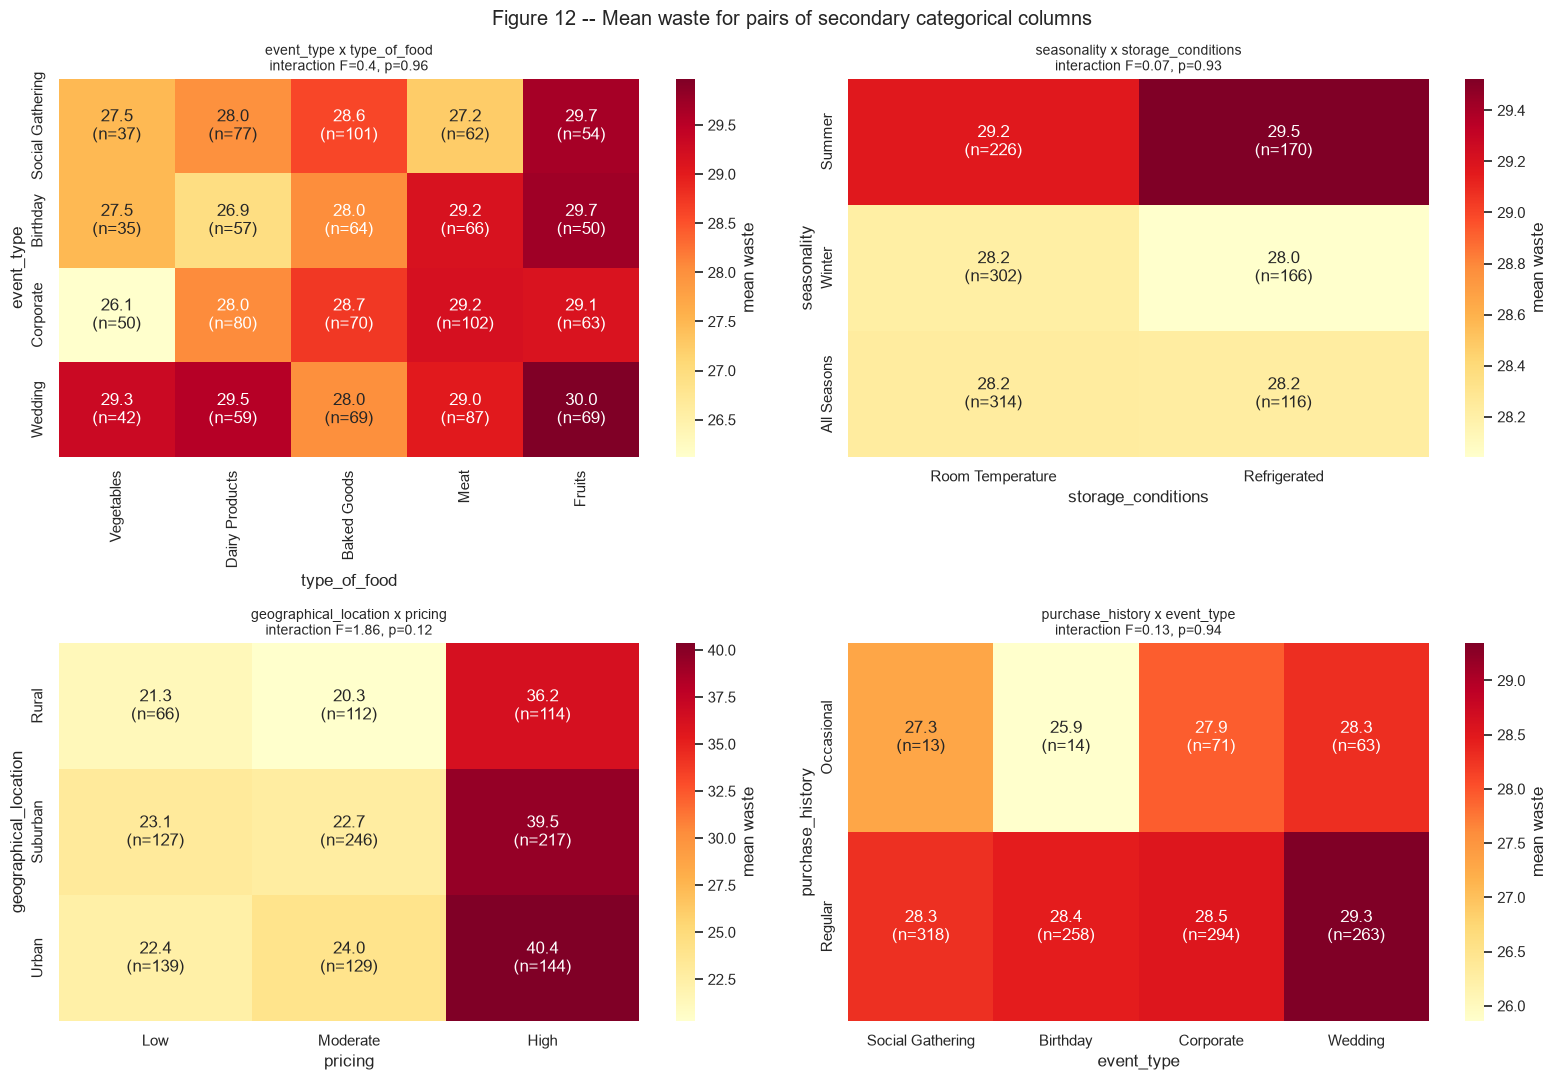

In [9]:
fig = E.fig_two_way_heatmaps(train_df); display(fig); plt.close(fig)

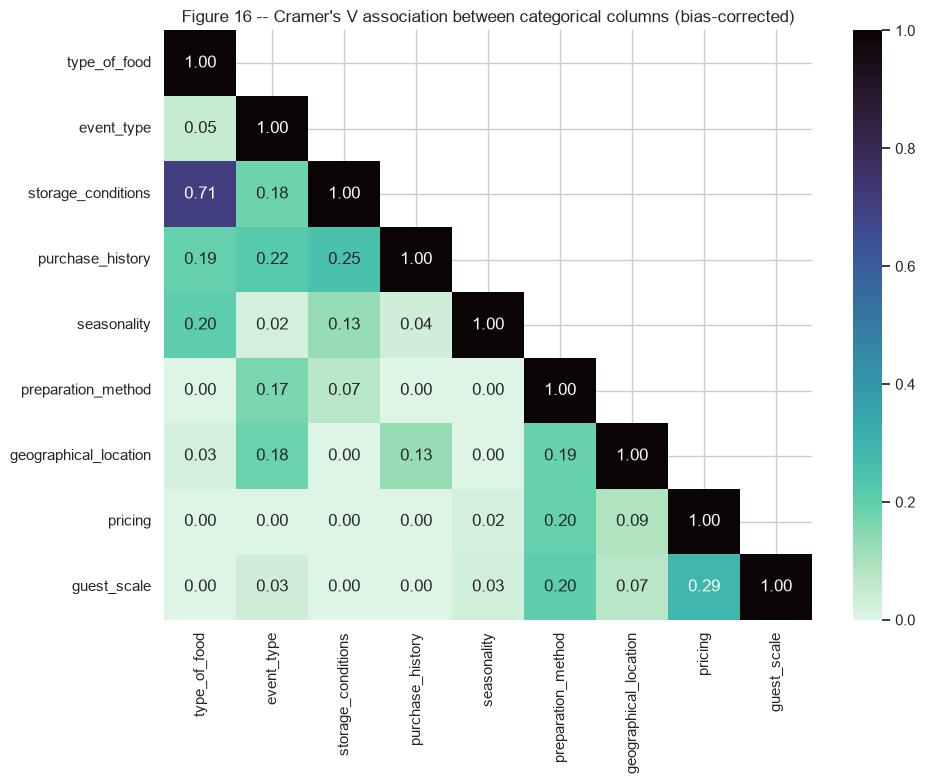

In [10]:
cv = E.cramers_v_matrix(train_df)
fig = E.fig_cramers_v(cv); display(fig); plt.close(fig)

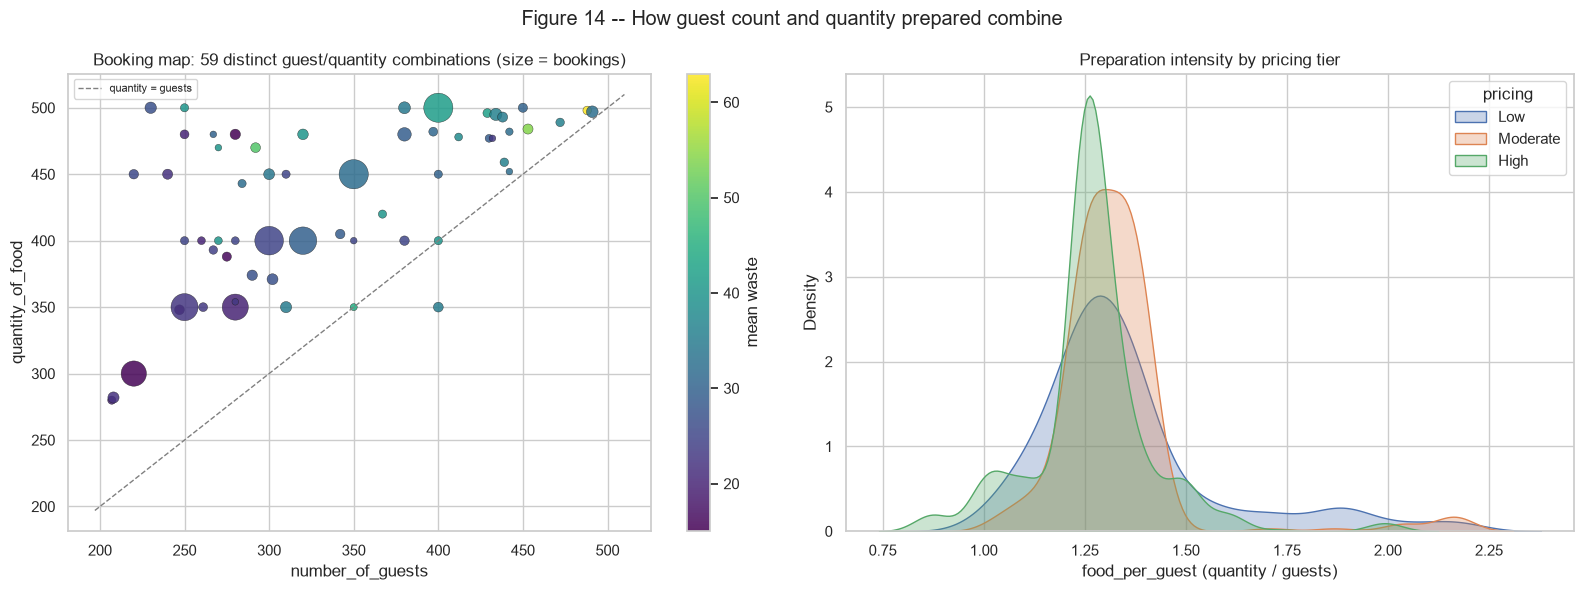

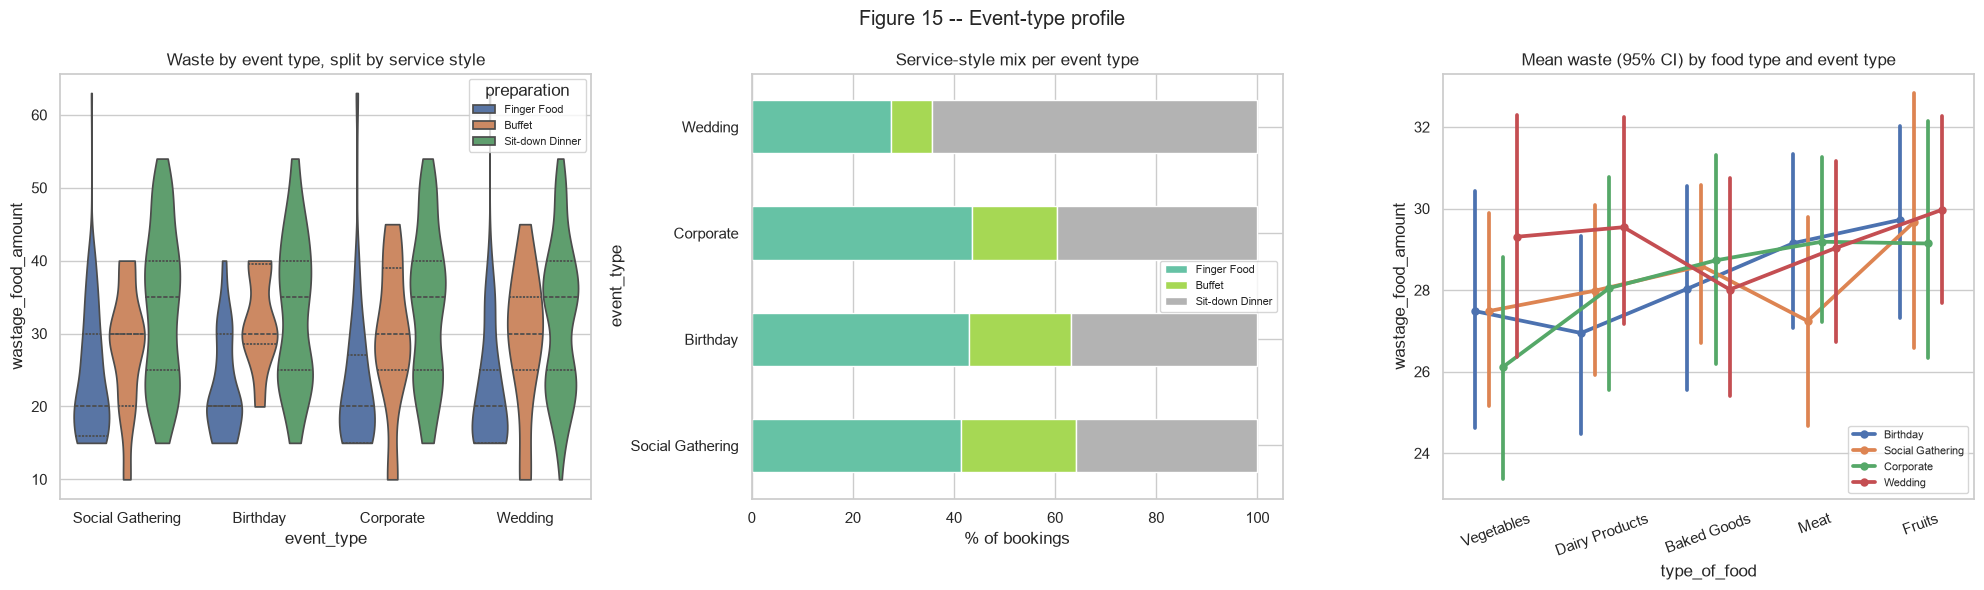

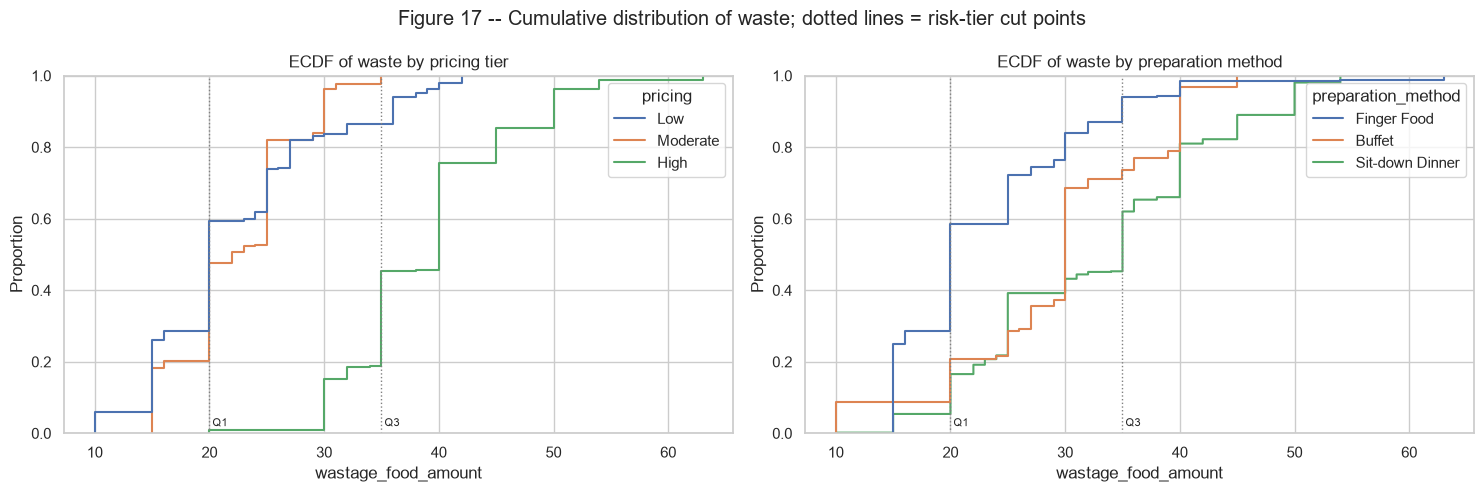

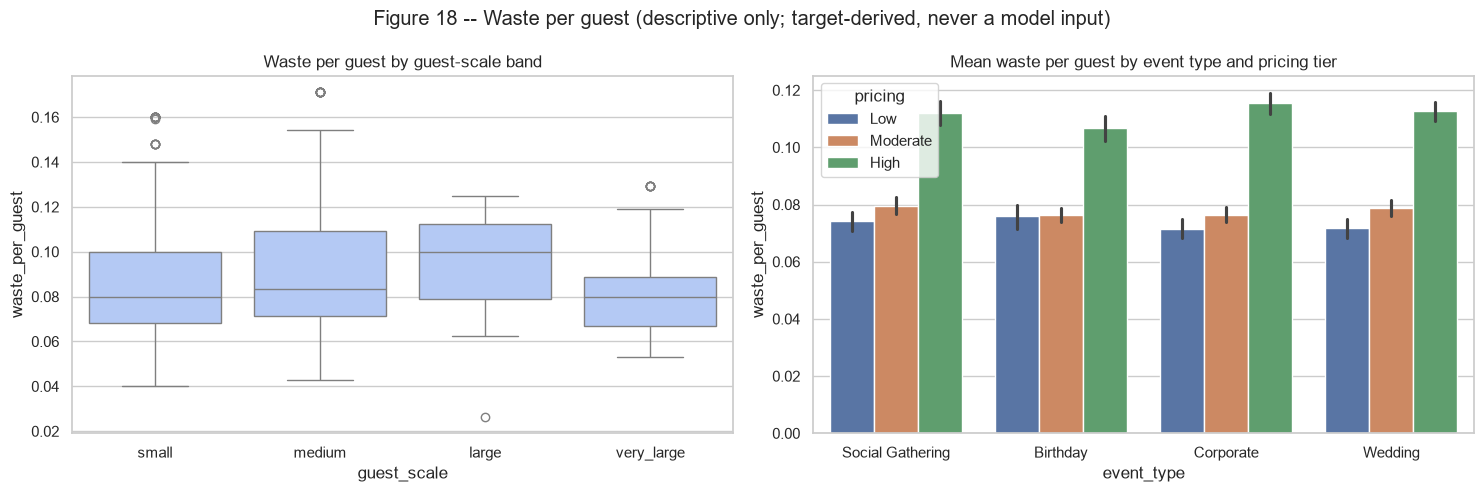

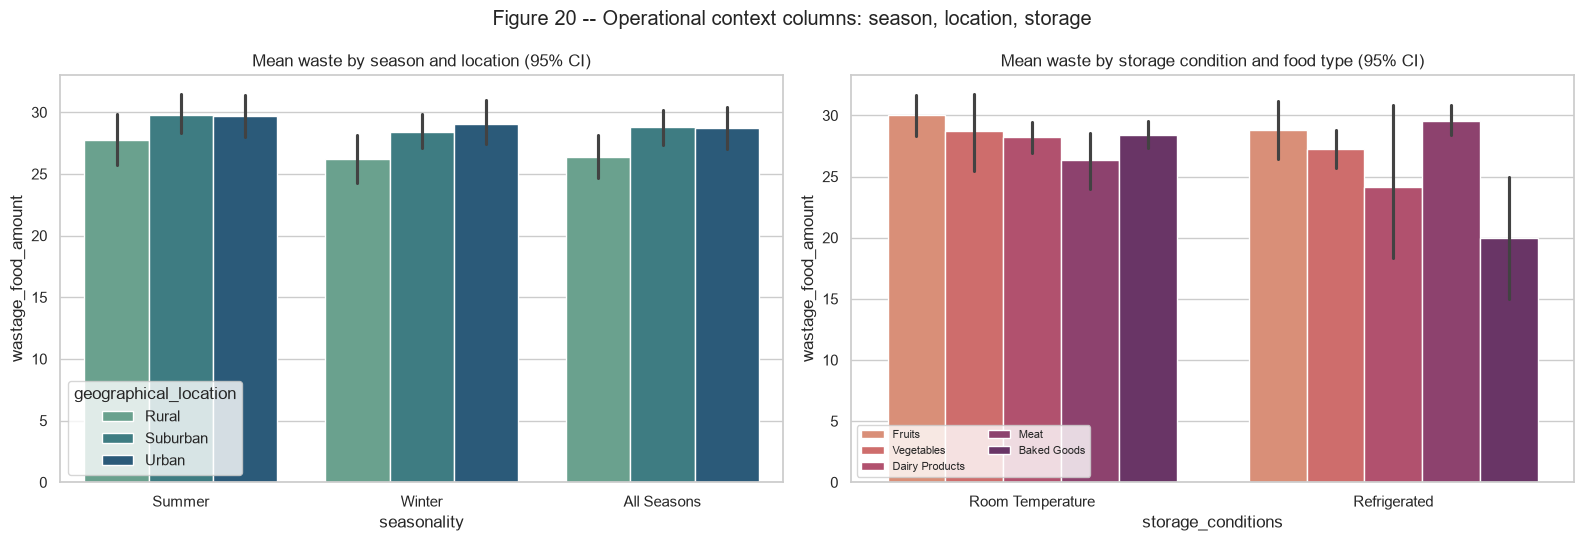

In [11]:
for fn in [E.fig_guests_quantity_map, E.fig_event_type_profile, E.fig_ecdf_by_segment,
           E.fig_waste_per_guest, E.fig_season_location_storage]:
    fig = fn(train_df); display(fig); plt.close(fig)

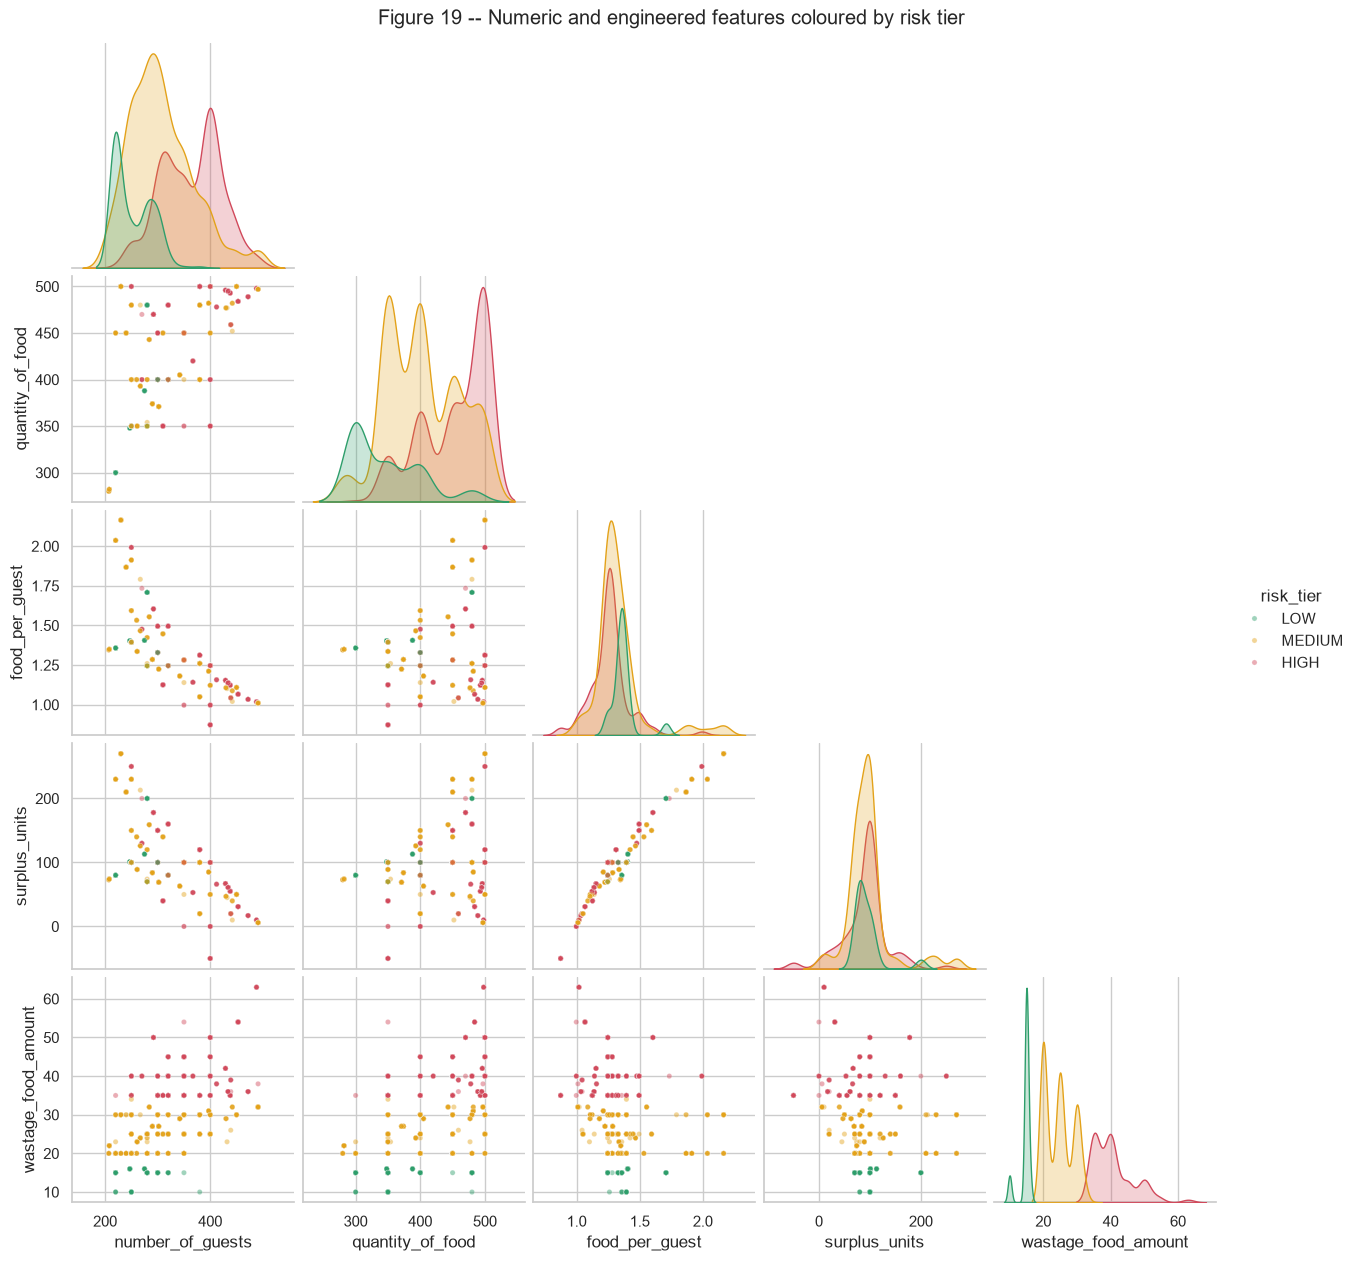

In [12]:
fig = E.fig_pairplot(train_df); display(fig); plt.close(fig)

**What the extended EDA changes in the modelling plan**

* Pricing (Cramer's V with tier ~0.55), guest-scale band (~0.38) and preparation method (~0.32) are the only strong
  associations with the risk tier. Food type, event type, storage, purchase history, seasonality and location are
  weak (V < 0.1). Location has a small main effect: Rural bookings have fewer HIGH tiers, partly because they prepare
  less food on average.
* Preparation method matters beyond the sit-down flag (Finger Food and Buffet differ), so it is now one-hot encoded
  in full: **33 design columns** instead of 30, which adds about 0.008 to cross-validated R2.
* The secondary columns show no meaningful two-way interactions (all interaction p > 0.1), apart from
  pricing x preparation method. A model that captures interactions automatically (tree ensembles) is therefore
  preferred over hand-built interaction terms.
* Waste depends on guests and quantity non-linearly *within* each pricing tier (Figure 14, ECDFs), so purely linear
  models are expected to under-fit.

## 1. Model selection and justification
Algorithms span four families, so the comparison says something about the *shape* of the problem and not
only about which library wins:

In [13]:
reg_specs = T.regression_candidates(D['scale_cols'])
clf_specs = T.classification_candidates(D['scale_cols'])
pd.DataFrame([{'task':'regression','model':n,'search':s['search'],'rationale':s['why']} for n,s in reg_specs.items()] +
             [{'task':'classification','model':n,'search':s['search'],'rationale':s['why']} for n,s in clf_specs.items()])

,task,model,search,rationale
0,regression,Naive (mean),NaN,Floor: any useful model must beat predicting t...
1,regression,Linear Regression,grid,Interpretable additive baseline; tests how far...
2,regression,KNN,grid,Non-parametric; bookings with similar guests/q...
3,regression,SVR,grid,RBF kernel captures smooth non-linearity; epsi...
4,regression,Random Forest,random,Bagged trees model the pricing x service inter...
5,regression,HistGradientBoosting,random,"Histogram-binned gradient boosting; fast, stro..."
6,regression,XGBoost,random,Regularised gradient boosting with histogram s...
7,classification,Dummy (most frequent),NaN,Floor: always predicts the majority tier (MEDI...
8,classification,Logistic Regression,grid,"Linear, calibrated probabilities; interpretabl..."
9,classification,KNN,grid,Instance-based; similar bookings should share ...


* **Baselines** (mean / most-frequent) give the floor every model must beat.
* **Linear / Logistic Regression**: interpretable and additive. They test whether the relationship is essentially linear.
* **KNN, SVM (RBF)**: non-parametric and kernel methods. They need feature scaling, which is done *inside* the CV
  pipeline so that every fold fits its own scaler.
* **Random Forest**: bagging of deep trees. It is robust and captures the pricing x service interaction with no manual terms.
* **HistGradientBoosting** and **XGBoost (`tree_method="hist"`)**: two histogram-based gradient-boosting
  implementations. Histogram binning suits this dataset well because guests, quantity and the target take only a
  small number of distinct values.

## 2-3. Model development and evaluation -- regression
Every model is trained twice: once with **library-default hyperparameters (baseline)**, and once after
**Grid / Randomized search** over 5-fold CV on the training partition. The 324-booking test partition is touched
only for the final scoring.

In [14]:
reg_table, reg_folds, reg_preds, reg_fitted, reg_params, reg_info, reg_searches, _ = T.run_regression(D)
reg_table[reg_table.stage=='baseline'].round(4)


=== Regression: baseline (default hyperparameters) ===


=== Regression: tuning ===


  tuned Linear Regression      grid     8 candidates x 5 folds in   0.2s -> CV r2=0.7671


  tuned KNN                    grid    28 candidates x 5 folds in   0.7s -> CV r2=0.7927


  tuned SVR                    grid    48 candidates x 5 folds in   4.2s -> CV r2=0.8256


  tuned Random Forest          random  25 candidates x 5 folds in  20.1s -> CV r2=0.9121


  tuned HistGradientBoosting   random  40 candidates x 5 folds in  18.8s -> CV r2=0.9091


  tuned XGBoost                random  50 candidates x 5 folds in   8.6s -> CV r2=0.9181


,model,stage,cv_R2_mean,cv_R2_std,cv_RMSE_mean,cv_MAE_mean,test_MAE,test_MSE,test_RMSE,test_R2,test_within_5_units_pct,fit_time_s
0,Naive (mean),baseline,-0.0058,0.0048,10.3965,8.7203,8.6218,107.9550,10.3901,-0.0019,29.6296,0.0013
1,Linear Regression,baseline,0.7670,0.0238,4.9972,3.7507,4.0272,28.5186,5.3403,0.7353,70.9877,0.0133
2,KNN,baseline,0.7864,0.0168,4.7868,3.5171,3.5648,23.1814,4.8147,0.7849,78.0864,0.0123
3,SVR,baseline,0.7479,0.0277,5.2031,3.7097,3.8184,30.4013,5.5137,0.7179,72.5309,0.0868
4,Random Forest,baseline,0.9030,0.0167,3.2138,2.0097,1.7845,8.7271,2.9542,0.9190,89.5062,0.4131
5,HistGradientBoosting,baseline,0.9026,0.0147,3.2229,2.1895,2.0214,8.4849,2.9129,0.9213,89.5062,0.5787
6,XGBoost,baseline,0.8934,0.0156,3.3683,2.2971,2.1442,9.6622,3.1084,0.9103,87.9630,0.0805


In [15]:
reg_table[reg_table.stage=='tuned'].sort_values('cv_R2_mean', ascending=False).round(4)

,model,stage,cv_R2_mean,cv_R2_std,cv_RMSE_mean,cv_MAE_mean,test_MAE,test_MSE,test_RMSE,test_R2,test_within_5_units_pct,fit_time_s
13,XGBoost,tuned,0.9181,0.0122,2.9527,2.0287,1.8870,7.3669,2.7142,0.9316,89.8148,0.1617
11,Random Forest,tuned,0.9121,0.0147,3.0615,2.0288,1.8914,8.1405,2.8532,0.9244,89.8148,1.7132
12,HistGradientBoosting,tuned,0.9091,0.0133,3.1120,2.2098,2.0157,7.7655,2.7867,0.9279,91.0494,0.4653
10,SVR,tuned,0.8256,0.0216,4.3240,3.0601,2.9948,19.8877,4.4596,0.8154,82.4074,0.1464
9,KNN,tuned,0.7927,0.0230,4.7164,3.3174,3.3920,22.0202,4.6926,0.7956,80.5556,0.0071
8,Linear Regression,tuned,0.7671,0.0237,4.9963,3.7534,4.0295,28.4835,5.3370,0.7357,70.9877,0.0104
7,Naive (mean),tuned,-0.0058,0.0048,10.3965,8.7203,8.6218,107.9550,10.3901,-0.0019,29.6296,0.0011


## 2-3. Model development and evaluation -- classification
Macro-F1 is the primary metric. Accuracy would be misleading here, because predicting MEDIUM every time already
scores about 50%. Accuracy, balanced accuracy, macro precision and recall, weighted F1, one-vs-rest ROC-AUC,
log-loss and the recall of the HIGH tier (the tier that triggers donation alerts) are all reported too.

In [16]:
best_reg, runner_reg, _ = T.select_best(reg_table, 'cv_R2_mean', ['Naive (mean)'])
clf_table, clf_folds, clf_preds, clf_probas, clf_fitted, clf_params, clf_info, clf_searches, _ = \
    T.run_classification(D, best_regressor=(best_reg, reg_fitted[best_reg]))
clf_table[clf_table.stage=='baseline'].round(4)


=== Classification: baseline (default hyperparameters) ===


=== Classification: tuning ===


  tuned Logistic Regression    grid    16 candidates x 5 folds in   0.8s -> CV f1_macro=0.8015


  tuned KNN                    grid    28 candidates x 5 folds in   0.7s -> CV f1_macro=0.8357


  tuned SVM (RBF)              grid    48 candidates x 5 folds in   8.2s -> CV f1_macro=0.8627


  tuned Random Forest          random  25 candidates x 5 folds in  25.4s -> CV f1_macro=0.8908


  tuned HistGradientBoosting   random  40 candidates x 5 folds in  91.0s -> CV f1_macro=0.8857


  tuned XGBoost                random  50 candidates x 5 folds in  42.1s -> CV f1_macro=0.8863


,model,stage,cv_macro_F1_mean,cv_macro_F1_std,cv_accuracy_mean,cv_balanced_acc_mean,test_accuracy,test_balanced_accuracy,test_precision_macro,test_recall_macro,test_macro_F1,test_weighted_F1,test_ROC_AUC_ovr,test_log_loss,test_HIGH_recall,fit_time_s
0,Dummy (most frequent),baseline,0.2247,0.0005,0.5085,0.3333,0.5000,0.3333,0.1667,0.3333,0.2222,0.3333,0.5000,18.0218,0.0000,0.0016
1,Logistic Regression,baseline,0.7847,0.0237,0.8176,0.7672,0.7994,0.7491,0.8090,0.7491,0.7703,0.7962,0.9207,0.4597,0.8644,0.0482
2,KNN,baseline,0.8266,0.0106,0.8532,0.8197,0.8364,0.7841,0.8150,0.7841,0.7974,0.8353,0.9185,1.3010,0.8559,0.0087
3,SVM (RBF),baseline,0.8445,0.0291,0.8701,0.8310,0.8519,0.8030,0.8483,0.8030,0.8214,0.8497,0.9380,0.3823,0.8898,0.2123
4,Random Forest,baseline,0.8887,0.0231,0.9119,0.8824,0.9012,0.8460,0.8891,0.8460,0.8639,0.8991,0.9672,0.3652,0.9407,0.1978
5,HistGradientBoosting,baseline,0.8782,0.0174,0.8995,0.8764,0.8858,0.8302,0.8559,0.8302,0.8415,0.8842,0.9724,0.3673,0.9407,1.4060
6,XGBoost,baseline,0.8791,0.0213,0.9018,0.8780,0.9043,0.8599,0.8869,0.8599,0.8719,0.9030,0.9713,0.2984,0.9492,0.1386


In [17]:
clf_table[clf_table.stage=='tuned'].sort_values('cv_macro_F1_mean', ascending=False).round(4)

,model,stage,cv_macro_F1_mean,cv_macro_F1_std,cv_accuracy_mean,cv_balanced_acc_mean,test_accuracy,test_balanced_accuracy,test_precision_macro,test_recall_macro,test_macro_F1,test_weighted_F1,test_ROC_AUC_ovr,test_log_loss,test_HIGH_recall,fit_time_s
11,Random Forest,tuned,0.8908,0.0256,0.9119,0.8833,0.9105,0.8585,0.9080,0.8585,0.8786,0.9083,0.9746,0.3193,0.9492,1.8015
13,XGBoost,tuned,0.8863,0.0201,0.9088,0.8764,0.9105,0.8727,0.9108,0.8727,0.8893,0.9096,0.9745,0.2341,0.9237,1.3019
12,HistGradientBoosting,tuned,0.8857,0.0206,0.9019,0.9068,0.8858,0.8854,0.8485,0.8854,0.8634,0.8877,0.9721,0.2607,0.9407,3.7754
10,SVM (RBF),tuned,0.8627,0.0249,0.8856,0.8547,0.8765,0.8162,0.8738,0.8162,0.8384,0.8735,0.9425,0.3561,0.9153,0.2193
9,KNN,tuned,0.8357,0.0138,0.8609,0.8285,0.8364,0.7904,0.8072,0.7904,0.7980,0.8361,0.9270,1.0816,0.8644,0.0070
8,Logistic Regression,tuned,0.8015,0.0280,0.8276,0.7919,0.7840,0.7436,0.7693,0.7436,0.7539,0.7818,0.9263,0.4523,0.8559,0.0995
7,Dummy (most frequent),tuned,0.2247,0.0005,0.5085,0.3333,0.5000,0.3333,0.1667,0.3333,0.2222,0.3333,0.5000,18.0218,0.0000,0.0028
14,XGBoost regressor + cut points,tuned,NaN,NaN,NaN,NaN,0.8148,0.8232,0.7737,0.8232,0.7848,0.8235,NaN,NaN,0.8983,NaN


## 4. Model performance comparison
Figures are regenerated from the objects above, saved to `figures/`, and shown inline.

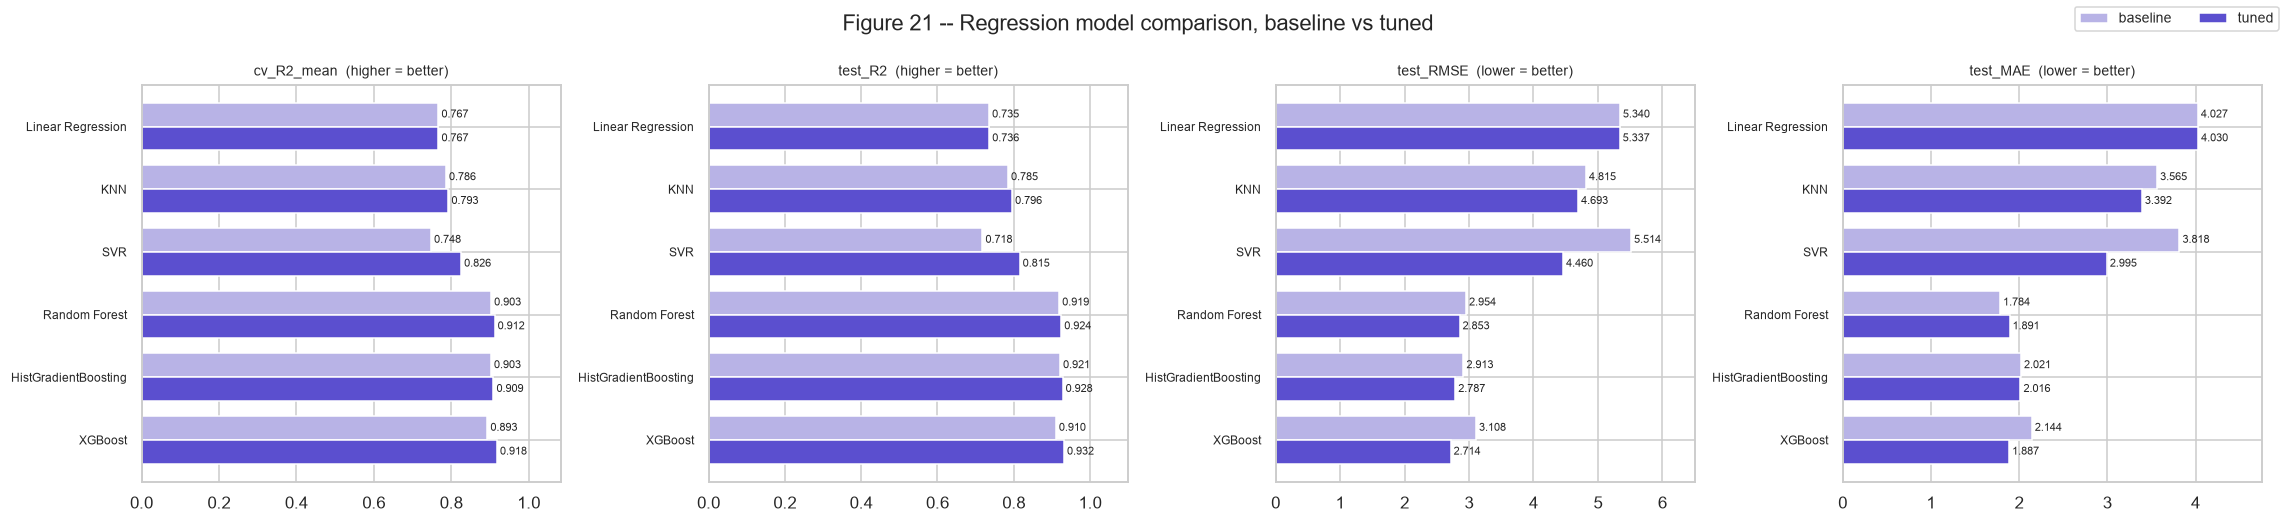

In [18]:
from sklearn.base import clone
T.FIG_DIR.mkdir(exist_ok=True)
T.fig_metric_comparison(reg_table[reg_table.model!='Naive (mean)'], ['cv_R2_mean','test_R2','test_RMSE','test_MAE'],
                        'Figure 21 -- Regression model comparison, baseline vs tuned', 'fig21_regression_comparison.png',
                        {'test_RMSE': False, 'test_MAE': False})
display(Image(T.FIG_DIR / 'fig21_regression_comparison.png'))

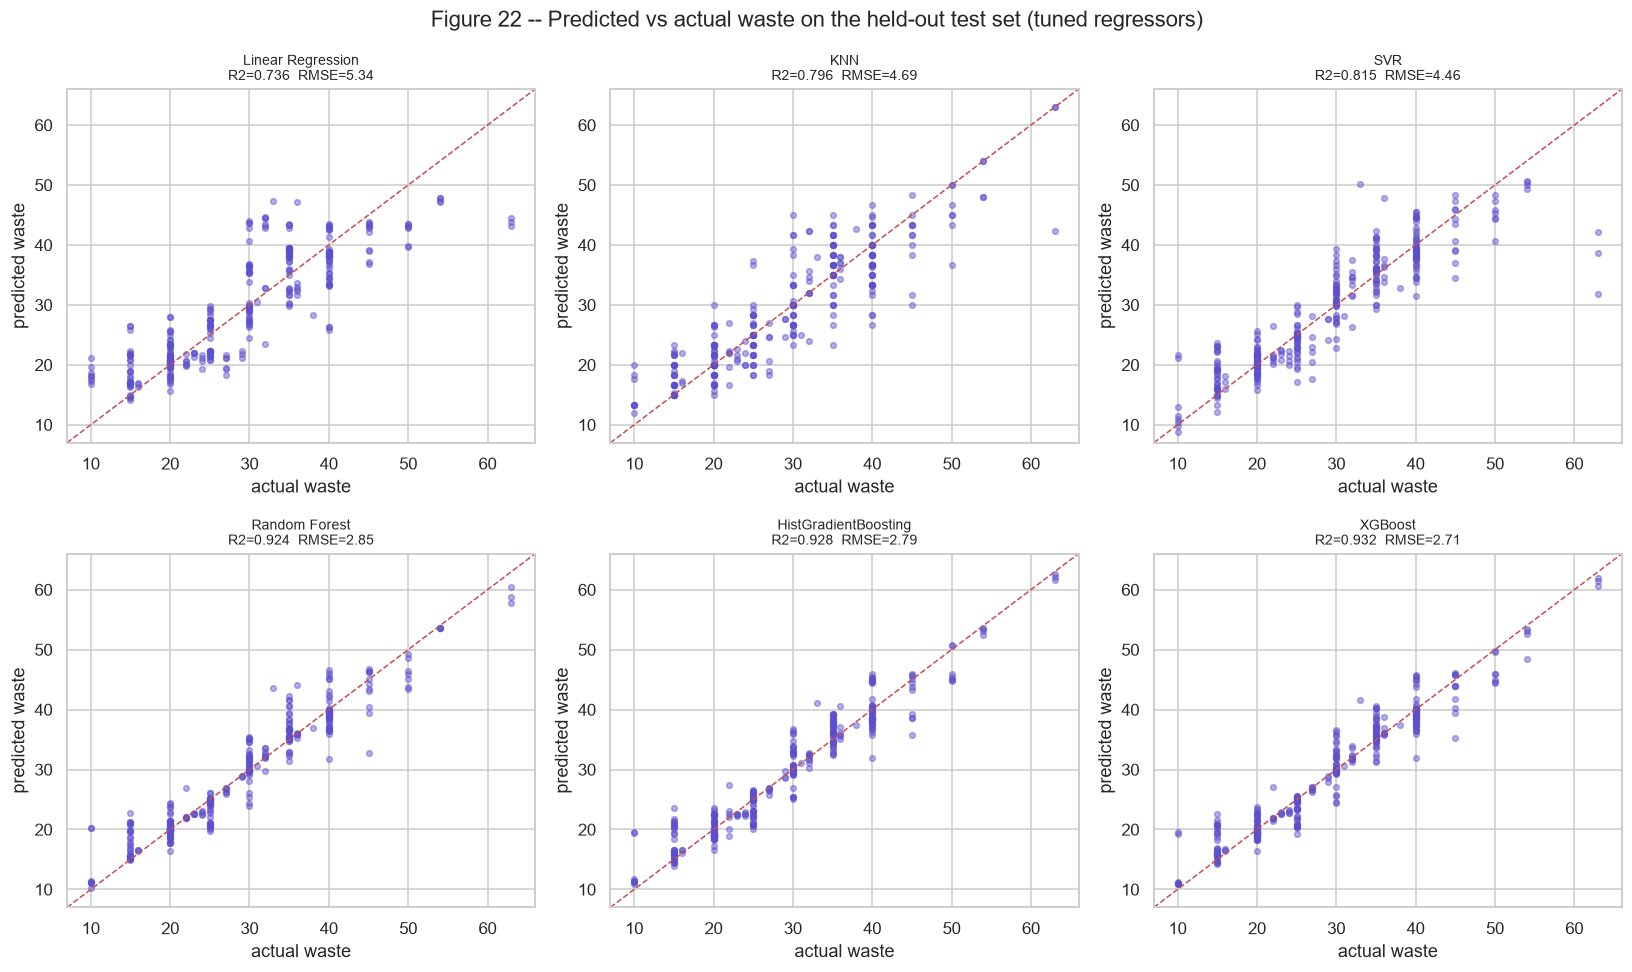

In [19]:
T.fig_pred_vs_actual(reg_preds, D['y_test_reg'], 'fig22_pred_vs_actual.png')
display(Image(T.FIG_DIR / 'fig22_pred_vs_actual.png'))

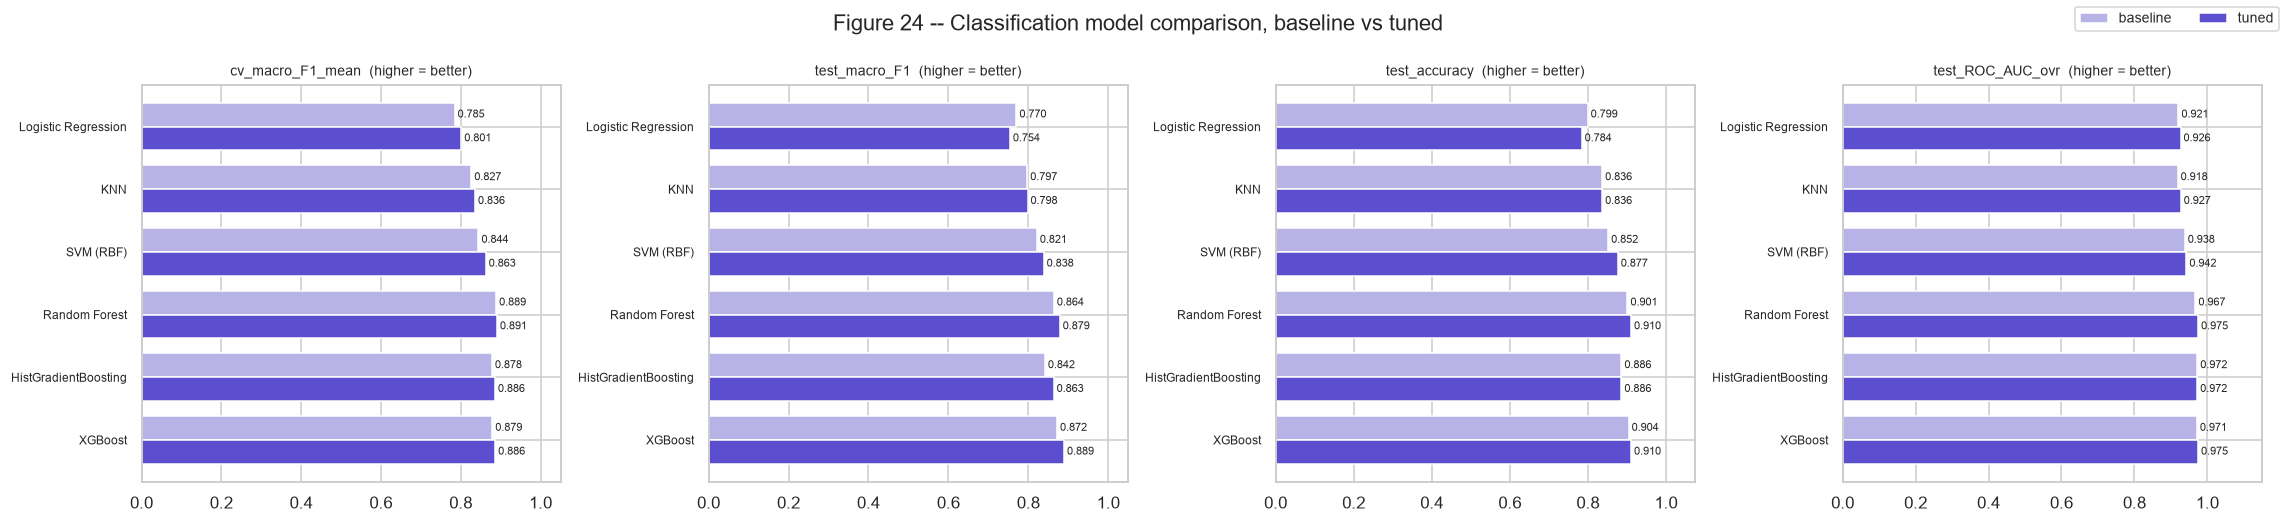

In [20]:
clf_plot = clf_table[~clf_table.model.str.contains('Dummy|cut points')]
T.fig_metric_comparison(clf_plot, ['cv_macro_F1_mean','test_macro_F1','test_accuracy','test_ROC_AUC_ovr'],
                        'Figure 24 -- Classification model comparison, baseline vs tuned', 'fig24_classification_comparison.png', {})
display(Image(T.FIG_DIR / 'fig24_classification_comparison.png'))

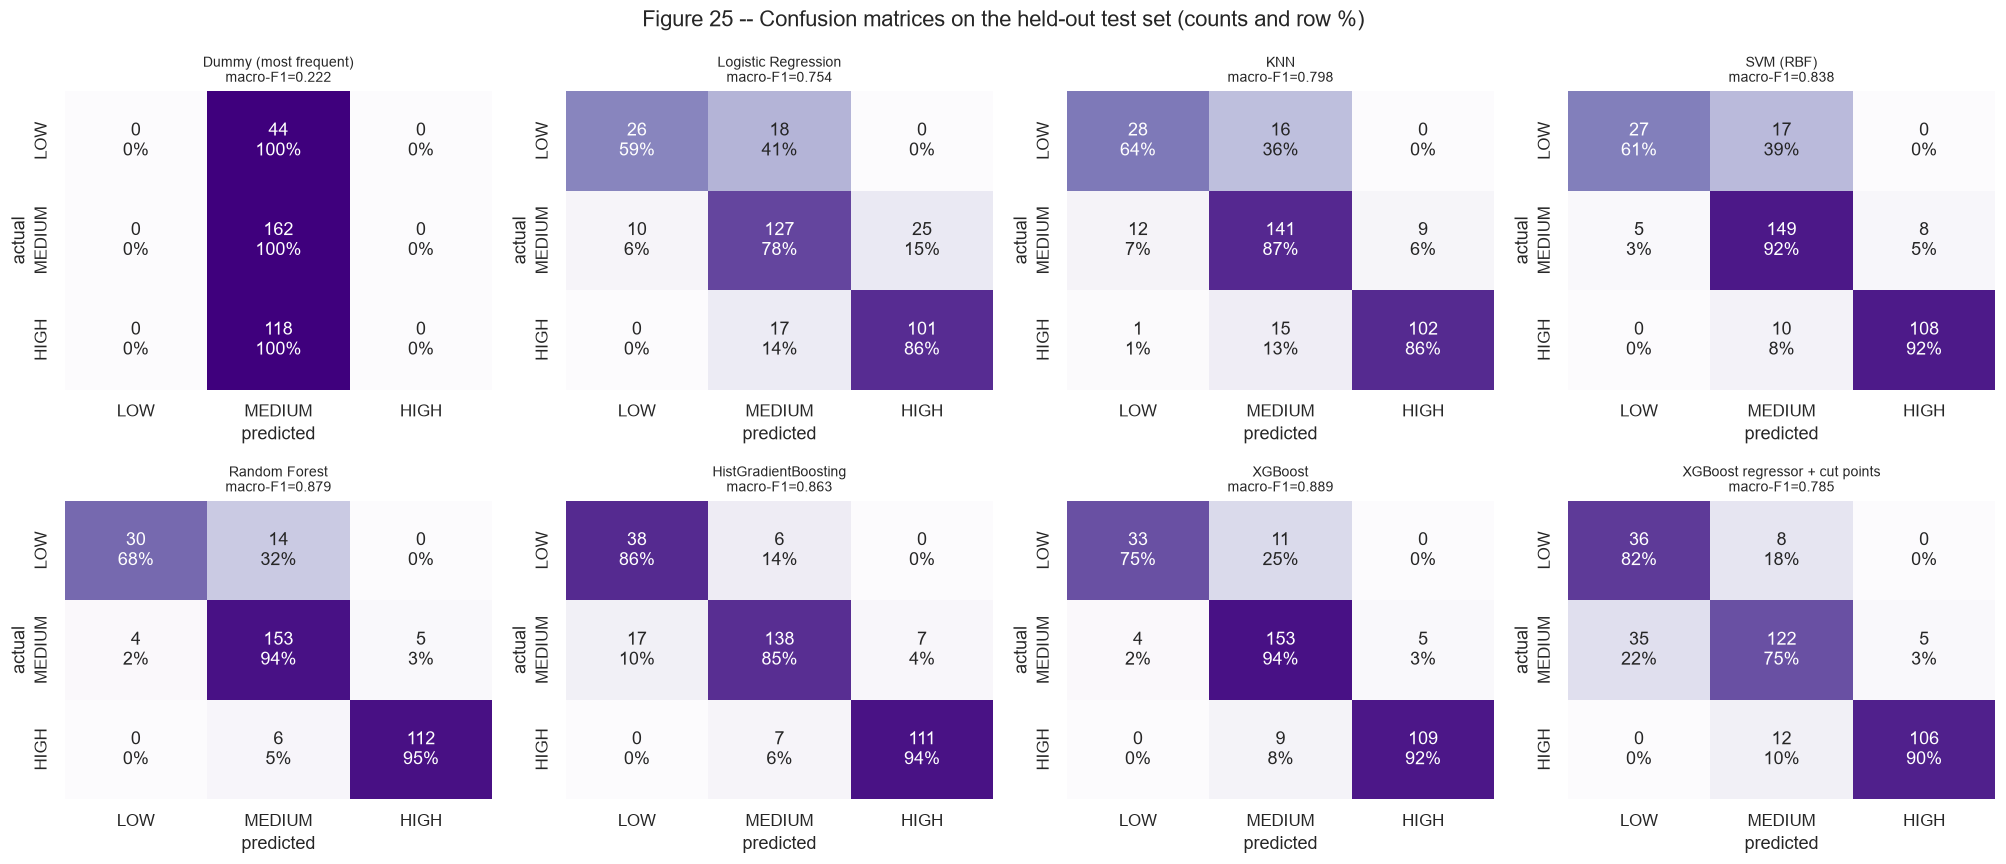

In [21]:
T.fig_confusion_grid(clf_preds, D['y_test_clf'], 'fig25_confusion_matrices.png')
display(Image(T.FIG_DIR / 'fig25_confusion_matrices.png'))

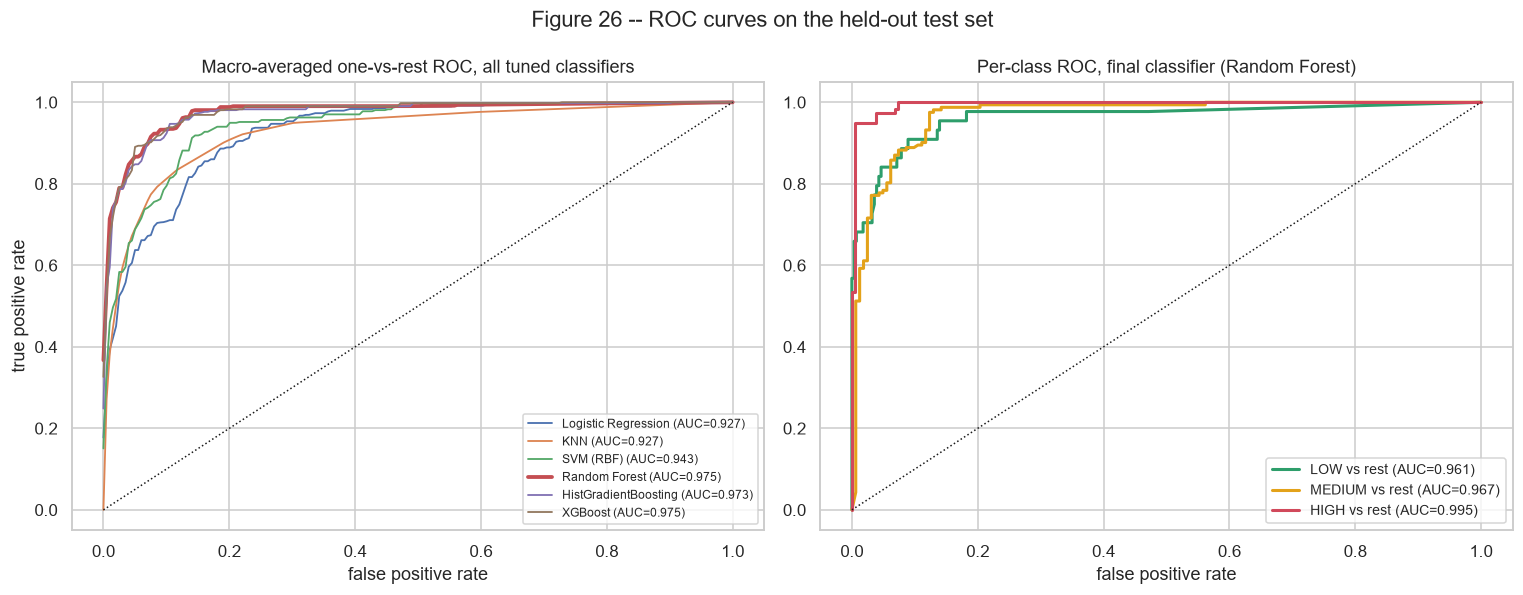

In [22]:
best_clf, runner_clf, _ = T.select_best(clf_table, 'cv_macro_F1_mean', ['Dummy (most frequent)'])
T.fig_roc(clf_probas, D['y_test_clf'], best_clf, 'fig26_roc_curves.png')
display(Image(T.FIG_DIR / 'fig26_roc_curves.png'))

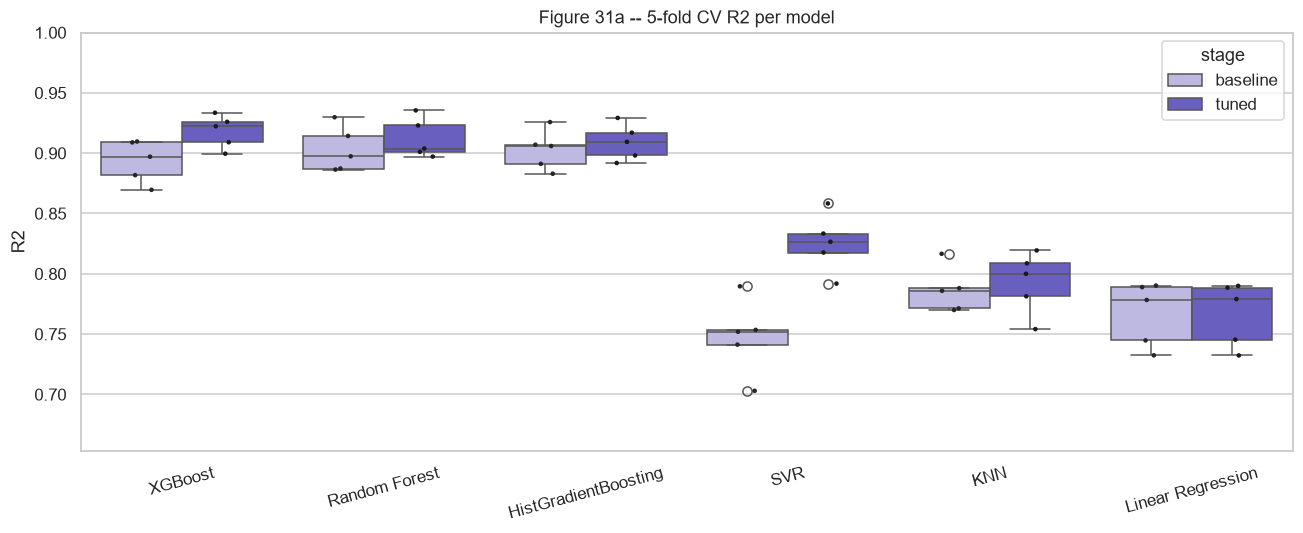

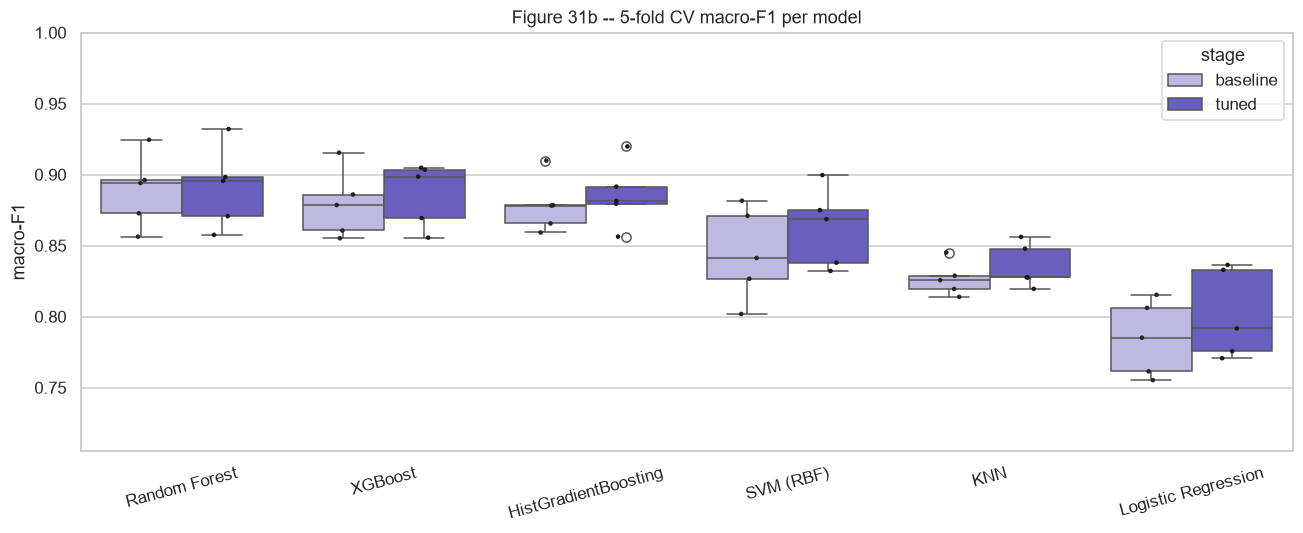

In [23]:
folds = pd.DataFrame(reg_folds + clf_folds)
T.fig_cv_distribution(folds[folds.model!='Naive (mean)'], 'regression', 'Figure 31a -- 5-fold CV R2 per model',
                      'fig31a_cv_scores_regression.png', 'R2')
T.fig_cv_distribution(folds[folds.model!='Dummy (most frequent)'], 'classification', 'Figure 31b -- 5-fold CV macro-F1 per model',
                      'fig31b_cv_scores_classification.png', 'macro-F1')
display(Image(T.FIG_DIR / 'fig31a_cv_scores_regression.png')); display(Image(T.FIG_DIR / 'fig31b_cv_scores_classification.png'))

### Strengths and limitations of each model

| Model | Strengths observed | Limitations observed |
|---|---|---|
| Linear / Logistic Regression | Fast, transparent coefficients, stable across folds | Additive form cannot represent the pricing x service interaction; lowest R2 / F1 of the real models |
| KNN | No training phase; captures local structure | Sensitive to scaling and to the one-hot dimensions; degrades on sparse guest/quantity combinations |
| SVR / SVM (RBF) | Largest gain from tuning (C, gamma, epsilon); smooth decision surface | Slower to tune; probability outputs need internal CV; still behind the tree ensembles |
| Random Forest | Strong out of the box; best HIGH-tier F1 (the donation-alert tier); little tuning needed | Large model on disk; averaging limits how sharply it can fit the round-number targets |
| HistGradientBoosting | Fast histogram boosting, competitive with no feature work | Most variable across random-search draws; slightly below XGBoost |
| XGBoost (hist) | Best regression on CV and test; best LOW-tier F1 and best test macro-F1; regularisation (lambda, alpha, gamma) controls over-fitting | Most hyperparameters; the default settings under-perform until tuned |

**Regressor + cut points** (classifying by thresholding the predicted amount) is clearly worse than a dedicated
classifier. 29% of bookings sit *exactly* on a cut point (20 or 35 units), so a small regression error flips the tier.
This justifies keeping two separate models.

## 5. Hyperparameter tuning and optimisation
Grid Search is used for small, discrete spaces (Linear/Ridge, KNN, SVM). Randomized Search with continuous
distributions is used for the tree ensembles (25-50 sampled configurations x 5 folds).

In [24]:
pd.DataFrame([{'task':'regression','model':n, **reg_info[n], 'best_params': reg_params[n]} for n in reg_params] +
             [{'task':'classification','model':n, **clf_info[n], 'best_params': clf_params[n]} for n in clf_params])

,task,model,search,candidates,seconds,best_params
0,regression,Linear Regression,grid,8,0.2,{'alpha': 1}
1,regression,KNN,grid,28,0.7,"{'n_neighbors': 3, 'p': 1, 'weights': 'uniform'}"
2,regression,SVR,grid,48,4.2,"{'C': 30, 'epsilon': 0.5, 'gamma': 'scale'}"
3,regression,Random Forest,random,25,20.1,"{'n_estimators': 700, 'min_samples_leaf': 2, '..."
4,regression,HistGradientBoosting,random,40,18.8,"{'l2_regularization': 5.140540420871591, 'lear..."
5,regression,XGBoost,random,50,8.6,"{'colsample_bytree': 0.8344620298315498, 'gamm..."
6,classification,Logistic Regression,grid,16,0.8,"{'C': 30, 'class_weight': None}"
7,classification,KNN,grid,28,0.7,"{'n_neighbors': 5, 'p': 1, 'weights': 'uniform'}"
8,classification,SVM (RBF),grid,48,8.2,"{'C': 10, 'class_weight': None, 'gamma': 'scale'}"
9,classification,Random Forest,random,25,25.4,"{'n_estimators': 700, 'min_samples_leaf': 2, '..."


,model,cv_R2_baseline,cv_R2_tuned,test_R2_baseline,test_R2_tuned,cv_R2_gain,test_R2_gain
0,HistGradientBoosting,0.9026,0.9091,0.9213,0.9279,0.0065,0.0067
1,KNN,0.7864,0.7927,0.7849,0.7956,0.0063,0.0108
2,Linear Regression,0.7670,0.7671,0.7353,0.7357,0.0001,0.0003
3,Naive (mean),-0.0058,-0.0058,-0.0019,-0.0019,0.0000,0.0000
4,Random Forest,0.9030,0.9121,0.9190,0.9244,0.0091,0.0054
5,SVR,0.7479,0.8256,0.7179,0.8154,0.0777,0.0976
6,XGBoost,0.8934,0.9181,0.9103,0.9316,0.0247,0.0213


,model,cv_macro_F1_baseline,cv_macro_F1_tuned,test_macro_F1_baseline,test_macro_F1_tuned,cv_macro_F1_gain,test_macro_F1_gain
0,Dummy (most frequent),0.2247,0.2247,0.2222,0.2222,0.0000,0.0000
1,HistGradientBoosting,0.8782,0.8857,0.8415,0.8634,0.0075,0.0218
2,KNN,0.8266,0.8357,0.7974,0.7980,0.0092,0.0006
3,Logistic Regression,0.7847,0.8015,0.7703,0.7539,0.0168,-0.0163
4,Random Forest,0.8887,0.8908,0.8639,0.8786,0.0021,0.0147
5,SVM (RBF),0.8445,0.8627,0.8214,0.8384,0.0182,0.0171
6,XGBoost,0.8791,0.8863,0.8719,0.8893,0.0072,0.0174


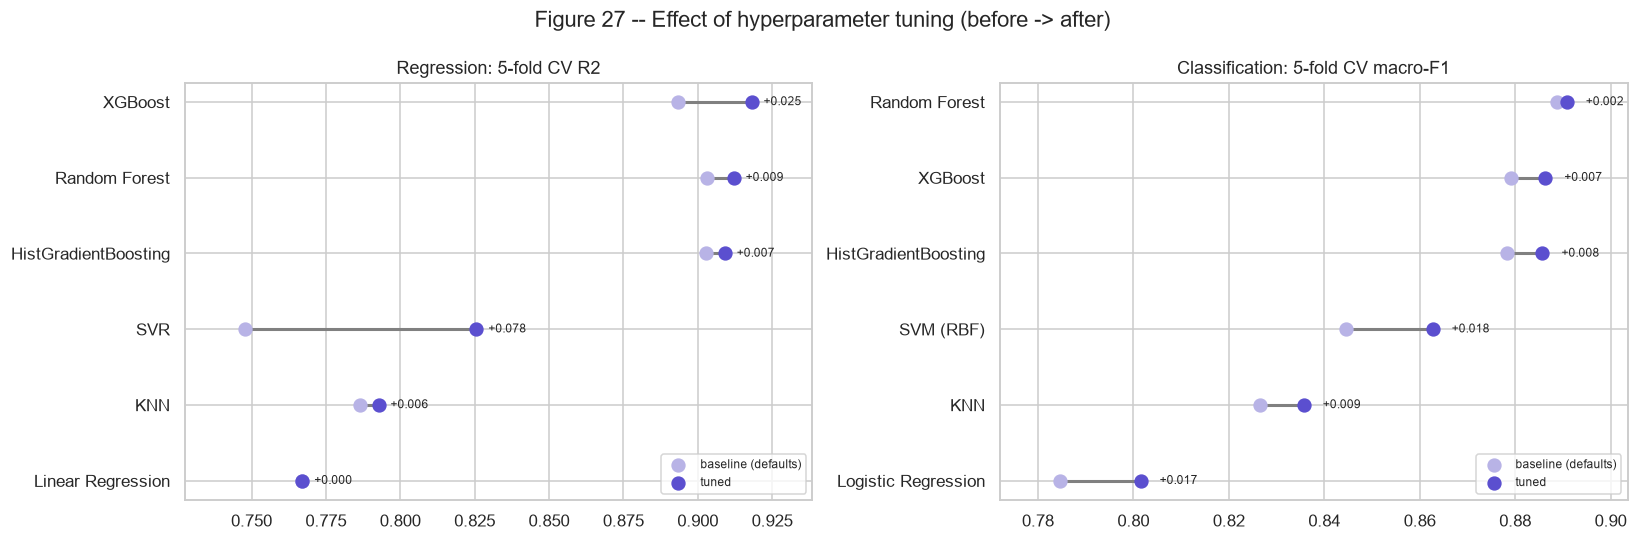

In [25]:
reg_ba = T.before_after(reg_table, 'cv_R2_mean', 'test_R2').round(4)
clf_ba = T.before_after(clf_table, 'cv_macro_F1_mean', 'test_macro_F1').round(4)
display(reg_ba); display(clf_ba)
T.fig_before_after(reg_ba, clf_ba, 'fig27_tuning_before_after.png')
display(Image(T.FIG_DIR / 'fig27_tuning_before_after.png'))

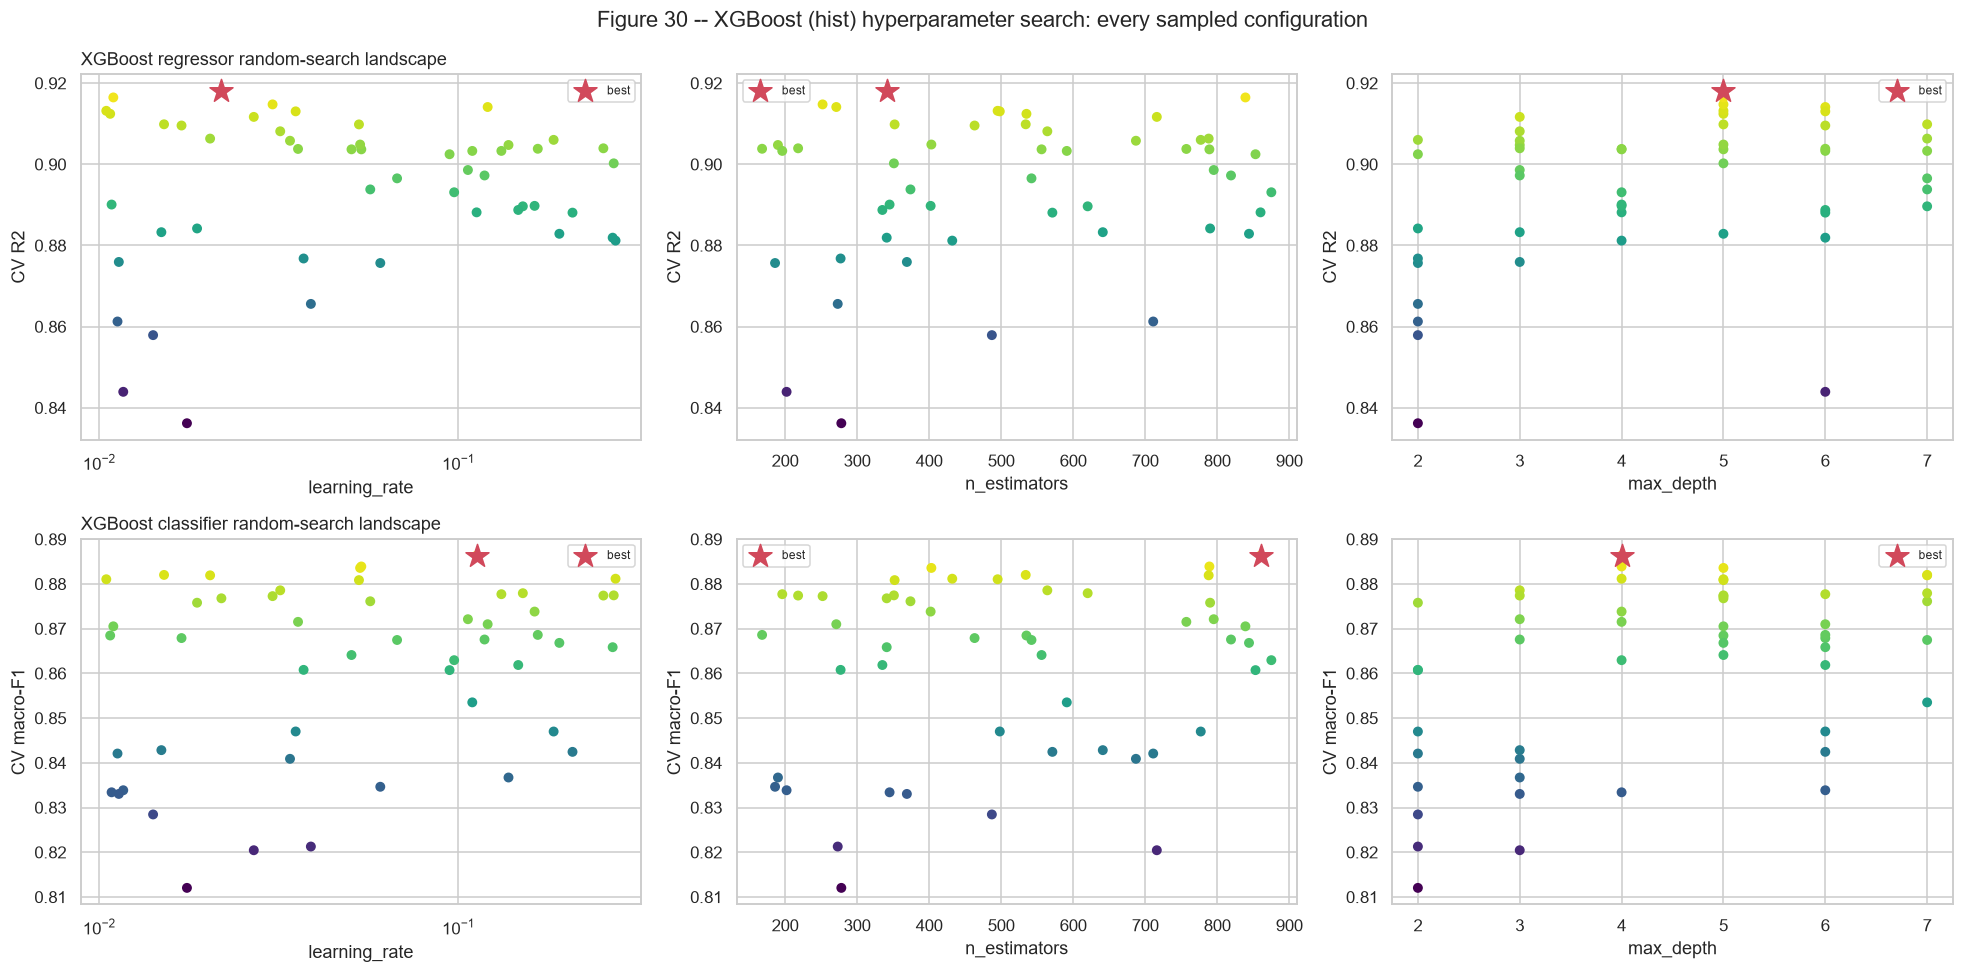

In [26]:
T.fig_xgb_search_landscape(reg_searches['XGBoost'], clf_searches['XGBoost'], 'fig30_xgboost_search_landscape.png')
display(Image(T.FIG_DIR / 'fig30_xgboost_search_landscape.png'))

**Reading:** tuning helps most where the defaults were poorly matched to the data. SVR gains the most, because
the default C is too small for a target in units. XGBoost is next: its default depth 6 and learning rate 0.3 over-fit,
and the tuned model uses shallower trees, a lower learning rate and more rounds. Random Forest and
HistGradientBoosting change only marginally, because their defaults were already close to optimal.

## 6. Final model selection
The rule fixed *before* looking at the test set: choose the model with the highest **tuned 5-fold CV score**. The
winner is then tested against the runner-up with the **Nadeau-Bengio corrected resampled t-test** on 5x3 repeated
CV. A naive paired t-test is over-confident here because the CV training sets overlap.

In [27]:
from sklearn.model_selection import RepeatedKFold, RepeatedStratifiedKFold
sig = pd.DataFrame([
    {'task':'regression','best':best_reg,'runner_up':runner_reg,
     **T.corrected_ttest(clone(reg_fitted[best_reg]), clone(reg_fitted[runner_reg]), D['X_train'], D['y_train_reg'],
                         RepeatedKFold(n_splits=5, n_repeats=3, random_state=P.SEED), 'r2')},
    {'task':'classification','best':best_clf,'runner_up':runner_clf,
     **T.corrected_ttest(clone(clf_fitted[best_clf]), clone(clf_fitted[runner_clf]), D['X_train'], D['y_train_clf'],
                         RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=P.SEED), 'f1_macro')},
])
print('Selected regressor :', best_reg, '| runner-up:', runner_reg)
print('Selected classifier:', best_clf, '| runner-up:', runner_clf)
sig.round(4)

Selected regressor : XGBoost | runner-up: Random Forest
Selected classifier: Random Forest | runner-up: XGBoost


,task,best,runner_up,mean_a,mean_b,mean_diff,t,p_value,folds,a_wins
0,regression,XGBoost,Random Forest,0.9182,0.9130,0.0052,1.1526,0.2684,15,11
1,classification,Random Forest,XGBoost,0.8865,0.8838,0.0027,0.4055,0.6912,15,8


              precision    recall  f1-score   support

         LOW      0.882     0.682     0.769        44
      MEDIUM      0.884     0.944     0.913       162
        HIGH      0.957     0.949     0.953       118

    accuracy                          0.910       324
   macro avg      0.908     0.858     0.879       324
weighted avg      0.911     0.910     0.908       324



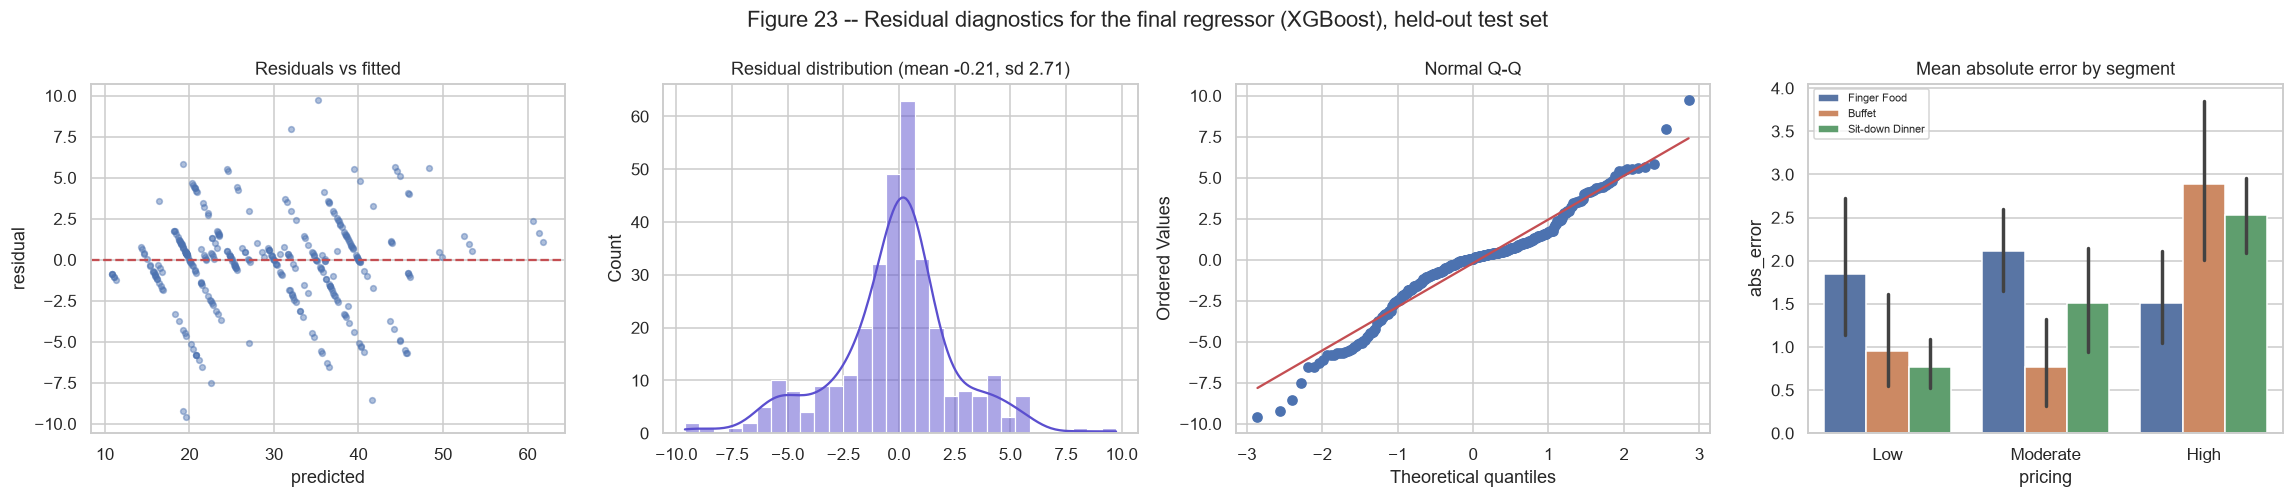

In [28]:
from sklearn.metrics import classification_report, r2_score, f1_score
print(classification_report(D['y_test_clf'], clf_preds[best_clf], target_names=T.LABELS, digits=3))
T.fig_residuals(best_reg, D['y_test_reg'], reg_preds[best_reg], test_df, 'fig23_residuals_final_regressor.png')
display(Image(T.FIG_DIR / 'fig23_residuals_final_regressor.png'))

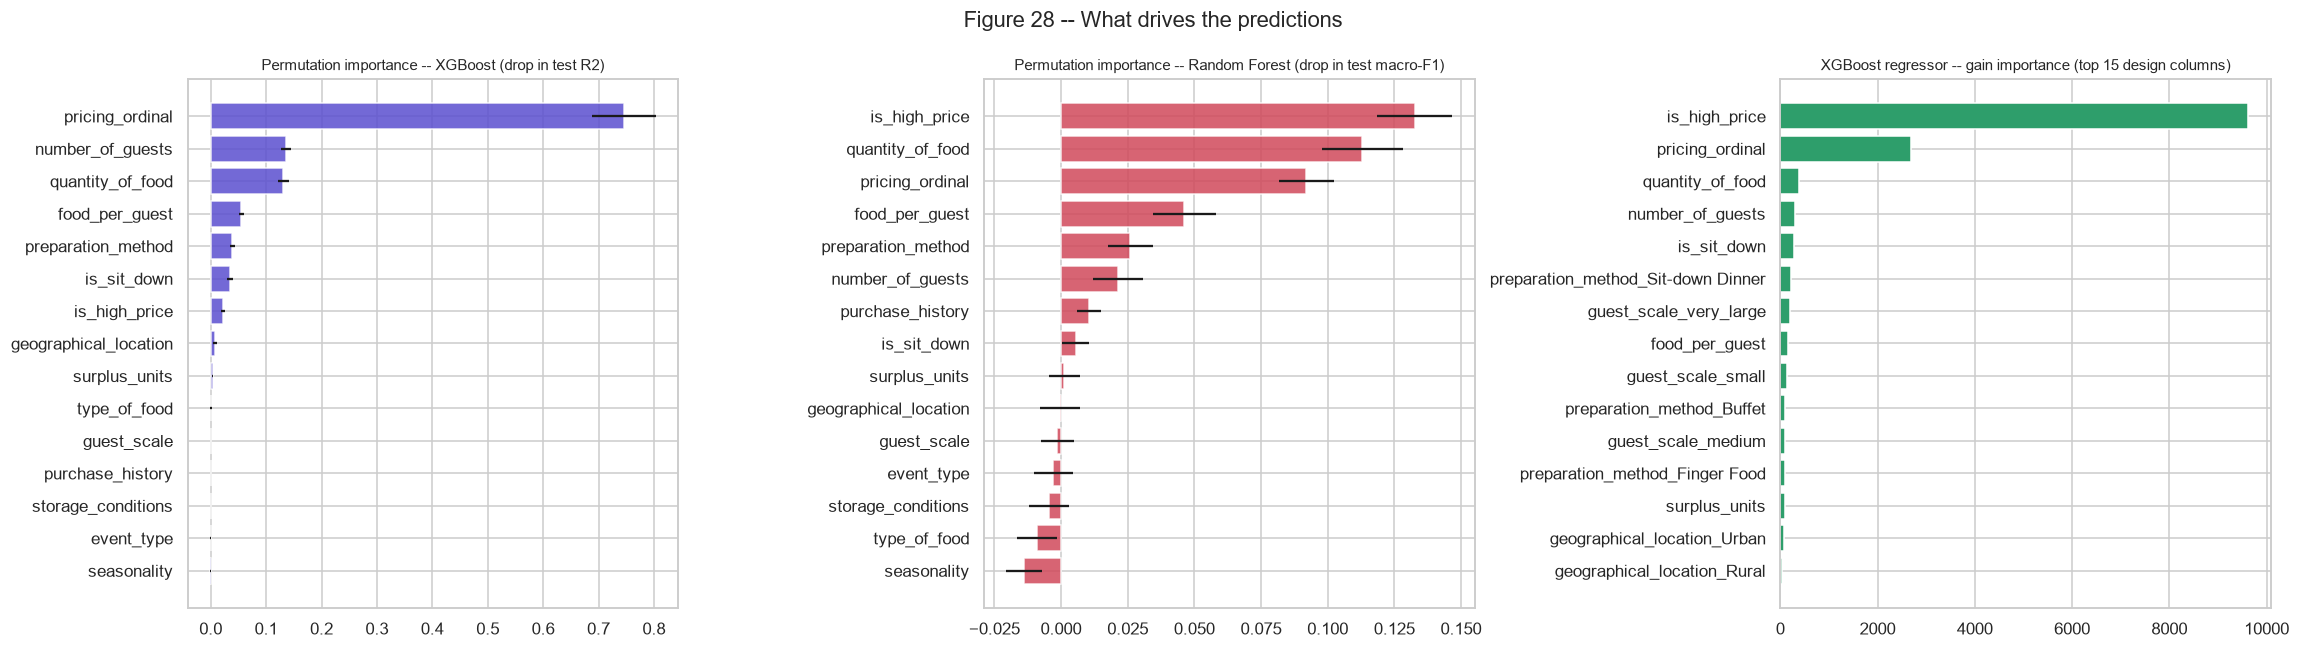

,feature,importance_mean,importance_std
0,pricing_ordinal,0.746009,0.057808
1,number_of_guests,0.135945,0.008633
2,quantity_of_food,0.131341,0.010643
3,food_per_guest,0.055404,0.005107
4,preparation_method,0.039170,0.004515
5,is_sit_down,0.035123,0.005052
6,is_high_price,0.021617,0.003669
7,geographical_location,0.007485,0.003392


In [29]:
reg_perm = T.grouped_permutation_importance(reg_fitted[best_reg], D['X_test'], D['y_test_reg'], r2_score)
clf_perm = T.grouped_permutation_importance(clf_fitted[best_clf], D['X_test'], D['y_test_clf'],
                                            lambda y, p: f1_score(y, np.asarray(p).astype(int), average='macro'))
gain = reg_fitted['XGBoost'].get_booster().get_score(importance_type='gain')
xgb_gain = pd.DataFrame({'feature': list(gain), 'gain': list(gain.values())}).sort_values('gain', ascending=False)
T.fig_feature_importance(reg_perm, clf_perm, xgb_gain, best_reg, best_clf, 'fig28_feature_importance_final.png')
display(Image(T.FIG_DIR / 'fig28_feature_importance_final.png'))
reg_perm.head(8)

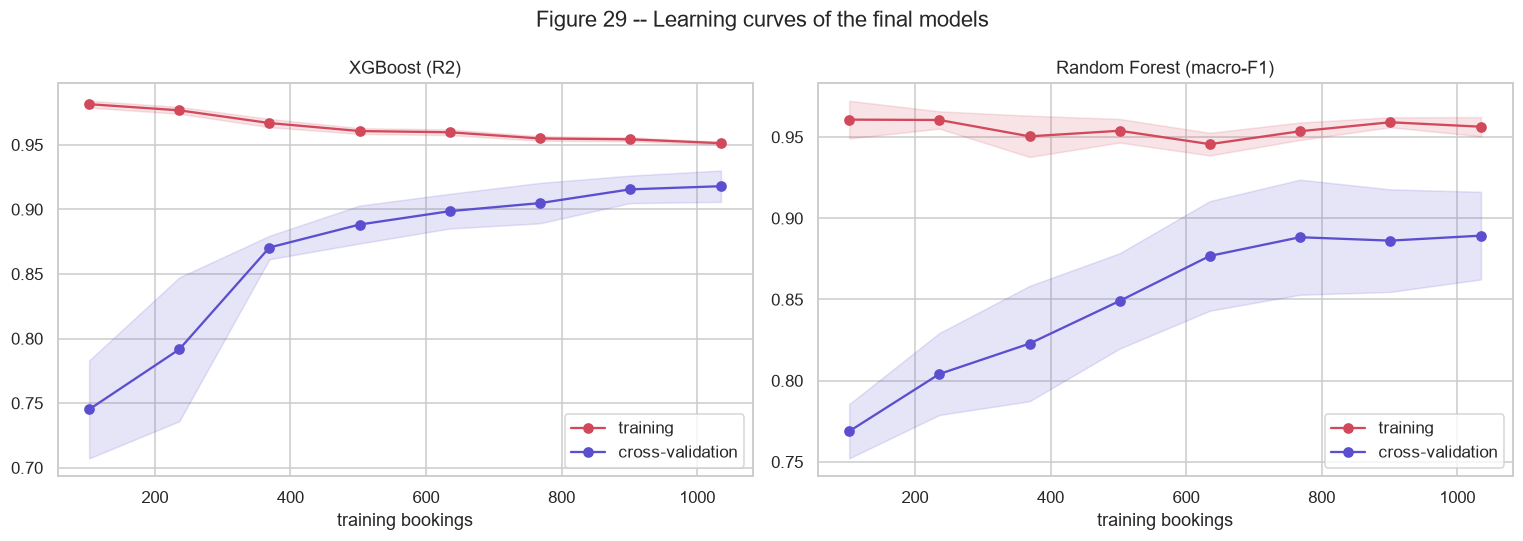

In [30]:
T.fig_learning_curves(clone(reg_fitted[best_reg]), clone(clf_fitted[best_clf]), D, best_reg, best_clf, 'fig29_learning_curves.png')
display(Image(T.FIG_DIR / 'fig29_learning_curves.png'))

In [31]:
ceiling = json.load(open(ROOT / 'out' / 'pipeline_manifest.json'))['attainable_ceiling']['implied_r2_ceiling']
best_row = reg_table[(reg_table.stage=='tuned') & (reg_table.model==best_reg)].iloc[0]
print(f"Final regressor test R2 = {best_row.test_R2:.4f}, irreducible-noise ceiling estimated in Review 2 ~ {ceiling}")
print(f"-> the model captures {100*best_row.test_R2/ceiling:.1f}% of the attainable explained variance")

Final regressor test R2 = 0.9316, irreducible-noise ceiling estimated in Review 2 ~ 0.9328
-> the model captures 99.9% of the attainable explained variance


**Justification.**
* The **XGBoost (hist)** regressor has the highest tuned CV R2 and the best test R2, RMSE and MAE. It comes close to
  the irreducible-noise ceiling estimated in Review 2, which leaves little room for any other model.
* For the risk tier, the CV-selected classifier and XGBoost are statistically indistinguishable (corrected t-test
  p > 0.05). Both reach a ROC-AUC of about 0.97, so the choice between them is not decisive. The dashboard exposes
  every tuned model so that this robustness can be checked interactively.
* The learning curves flatten, so the remaining error is noise in the labels rather than a lack of data or of model
  capacity.

## 7. End-to-end product: booking -> forecast -> tier -> action -> alert
The dashboard (`app/streamlit_app.py`) uses exactly this inference path: `pipeline.prepare_inputs`, followed by the
saved models in `models/`. Those models are written by `python src/train_models.py`, which runs the same code shown above.

In [32]:
import joblib
meta = json.load(open(ROOT / 'models' / 'metadata.json'))
regressor = joblib.load(ROOT / 'models' / 'regressor.pkl')
classifier = joblib.load(ROOT / 'models' / 'classifier.pkl')
bookings = pd.DataFrame([
    dict(number_of_guests=460, quantity_of_food=495, pricing='High', event_type='Wedding', preparation_method='Sit-down Dinner',
         type_of_food='Meat', storage_conditions='Refrigerated', purchase_history='Regular', seasonality='Winter', geographical_location='Urban'),
    dict(number_of_guests=300, quantity_of_food=380, pricing='Moderate', event_type='Corporate', preparation_method='Buffet',
         type_of_food='Vegetables', storage_conditions='Room Temperature', purchase_history='Occasional', seasonality='Summer', geographical_location='Suburban'),
    dict(number_of_guests=220, quantity_of_food=300, pricing='Low', event_type='Birthday', preparation_method='Finger Food',
         type_of_food='Baked Goods', storage_conditions='Refrigerated', purchase_history='Regular', seasonality='All Seasons', geographical_location='Rural'),
])
X = P.prepare_inputs(bookings, meta['design_matrix_columns'], meta['feature_columns_raw']).astype(float)
out = bookings[['number_of_guests','quantity_of_food','pricing','preparation_method']].copy()
out['predicted_waste'] = regressor.predict(X).round(1)
out['risk_tier'] = [T.LABELS[i] for i in classifier.predict(X).astype(int)]
out['action'] = out['risk_tier'].map(P.ACTION_MAP)
out['donation_alert'] = out['risk_tier'].eq('HIGH')
out

,number_of_guests,quantity_of_food,pricing,preparation_method,predicted_waste,risk_tier,action,donation_alert
0,460,495,High,Sit-down Dinner,50.500000,HIGH,Reduce quantity of food by 15-20% and flag for...,True
1,300,380,Moderate,Buffet,25.700001,MEDIUM,Reduce quantity of food by 10-15%,False
2,220,300,Low,Finger Food,14.800000,LOW,Normal preparation,False


Launch the interactive dashboard with:

```
./venv/Scripts/python -m streamlit run app/streamlit_app.py
```